# MIE 446 Aerospace Structures
## Lecture 03 — Beam reactions, stress and deflection

**90-minute guided lesson · Dr. Ehsan Roohi · Fall 2026**

Lecture 02 converted distributed loads into a force and a load centroid. Today we ask what the structure must do with that load: **supports → reactions → internal shear and moment → stress → deflection**. The main model is a cantilever representing an idealized wing-root attachment. We compare two other supports without trying to cover every load/support combination.

By the end you should draw a free body, identify reaction unknowns, check equilibrium, calculate nominal bending stress and deflection, and explain why zero displacement at a clamp does not mean zero stress.

| Minutes | Activity | Evidence |
|---|---|---|
| 0–8 | Retrieve Lecture 02: force and centroid | Predict a root moment |
| 8–23 | Supports and reaction unknowns | Label a free-body diagram |
| 23–38 | Example A: cantilever and internal resultants | Calculate reaction, shear and moment |
| 38–53 | Stress across the section | Compute tension, compression and shear |
| 53–66 | Curvature and displacement | Calculate tip deflection and compare app |
| 66–78 | Example B: equivalent uniform load | Explain a same-force difference |
| 78–86 | Example C: support comparison | Explain why equilibrium is insufficient for fixed–fixed |
| 86–90 | Wing connection and exit ticket | Claim, number, check and limitation |

**Before class:** save a copy in Drive, run the setup, and open Wing Lab in another tab. All figures and baseline answers are saved, so the lesson is readable before execution. Python calculations run in Colab without installing CAD. App links open a new study with precisely the example inputs; they do not send edits back to this notebook. Modes, torsion and local buckling are for later lessons.

**Instructor pacing:** explain the annotated geometry and one worked calculation in class; the extra algebra is supporting reading, not a request to derive every formula in 90 minutes. Figures 5C and 5D help students inspect the calculation if needed. The circular-tube torsion section is optional and the beam software remains a bending-only model.

**Software:** [Open the beam workspace](https://ehsan-roohi.github.io/Aerospace-Structures/wing-lab.html) · [Lecture 02](https://colab.research.google.com/github/Ehsan-Roohi/Aerospace-Structures/blob/main/notebooks/MIE446_Lecture_02_Finite_Wings_and_Load_Paths.ipynb). The app and this notebook use mm, N and MPa. One MPa equals one N/mm².

In [1]:
#@title 0. Setup and clear plotting conventions
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon, Circle, FancyArrowPatch
plt.rcParams.update({'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 14,
                     'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
L, b, h, E, P = 450.0, 20.0, 10.0, 2000.0, 2.0
A = b*h
I = b*h**3/12
EI = E*I
x = np.linspace(0,L,401)
def arrow(ax, start, end, color='#9a2786'):
    ax.annotate('', xy=end, xytext=start,
                arrowprops=dict(arrowstyle='-|>', color=color, lw=2.5, mutation_scale=20))
def support(ax, at, kind):
    if kind == 'fixed':
        ax.add_patch(Rectangle((at-9,-14),9,28,facecolor='#c4d9cf',edgecolor='#176441',lw=2))
        for y in np.arange(-12,15,6): ax.plot([at-9,at-17],[y,y-5],color='#176441')
    else:
        ax.add_patch(Polygon([[at,0],[at-12,-12],[at+12,-12]],facecolor='#c4d9cf',edgecolor='#176441',lw=2))
        if kind == 'roller':
            for dx in [-7,7]: ax.add_patch(Circle((at+dx,-16),3,facecolor='white',edgecolor='#176441'))
def clean_beam(ax, title):
    ax.plot([0,L],[0,0],color='#19394e',lw=5)
    ax.set(xlim=(-55,510),ylim=(-55,65),title=title)
    ax.axis('off')
print(f'L={L:g} mm; b={b:g} mm; h={h:g} mm; E={E:g} MPa (assumed teaching value)')
print(f'A={A:g} mm²; I={I:.3f} mm⁴; EI={EI:.3f} N mm²')

def dimension(ax, start, end, label, offset=(0,0), color='#19394e', rotation=0):
    ax.annotate('', xy=end, xytext=start,
                arrowprops=dict(arrowstyle='<->', color=color, lw=1.6))
    centre=(np.asarray(start)+np.asarray(end))/2+np.asarray(offset)
    ax.text(*centre,label,ha='center',va='center',color=color,fontsize=13,rotation=rotation,
            bbox=dict(facecolor='white',edgecolor='none',pad=1))

L=450 mm; b=20 mm; h=10 mm; E=2000 MPa (assumed teaching value)
A=200 mm²; I=1666.667 mm⁴; EI=3333333.333 N mm²


### A symbol map before we start

**x** is distance along the beam, starting at the root. **z** is height in a cross-section, measured upward from its neutral axis. **y** is the transverse width direction. **v** is displacement downward, whereas **V** is the internal shear force. Neither is the flight speed in this lesson.

| Symbol | Meaning | Unit | Where it appears |
|---|---|---|---|
| L, x | Full length and cut station | mm | Side view |
| b, h | Section width and vertical depth | mm | Cross-section |
| c = h/2, z | Extreme-fibre distance and a selected fibre height | mm | Cross-section |
| P, q | Point force and distributed force per length | N, N/mm | Load drawing |
| Rₐ, Cₐ | Root force and root reaction couple | N, N mm | Whole-beam free body |
| V, M | Internal shear and signed sagging bending moment | N, N mm | A cut and diagrams |
| E, I, EI | Material modulus, second moment of area and bending stiffness | MPa, mm⁴, N mm² | Section and curvature calculation |
| εₓ, σₓ, τₓz | Longitudinal strain, longitudinal stress and transverse shear stress | dimensionless, MPa, MPa | Material fibres and stress profiles |
| v, θ, κ | Displacement, slope/rotation and curvature | mm, rad, 1/mm | Deflected beam |

Use the figure first, then the equation, then the numerical substitution. A subscript names a direction or station; it is not an extra multiplier. The figure dimensions are teaching inputs, not measured properties of the full course wing.

Figures 0A and 0B locate these symbols in views of the beam and its section. Figure 0A illustrates possible point and distributed loads; Example A below uses only the point force. Blue shows motion, purple shows applied loading, green shows support actions, and orange shows cut actions or a local tangent. Material properties and section stiffness are not extra applied forces.

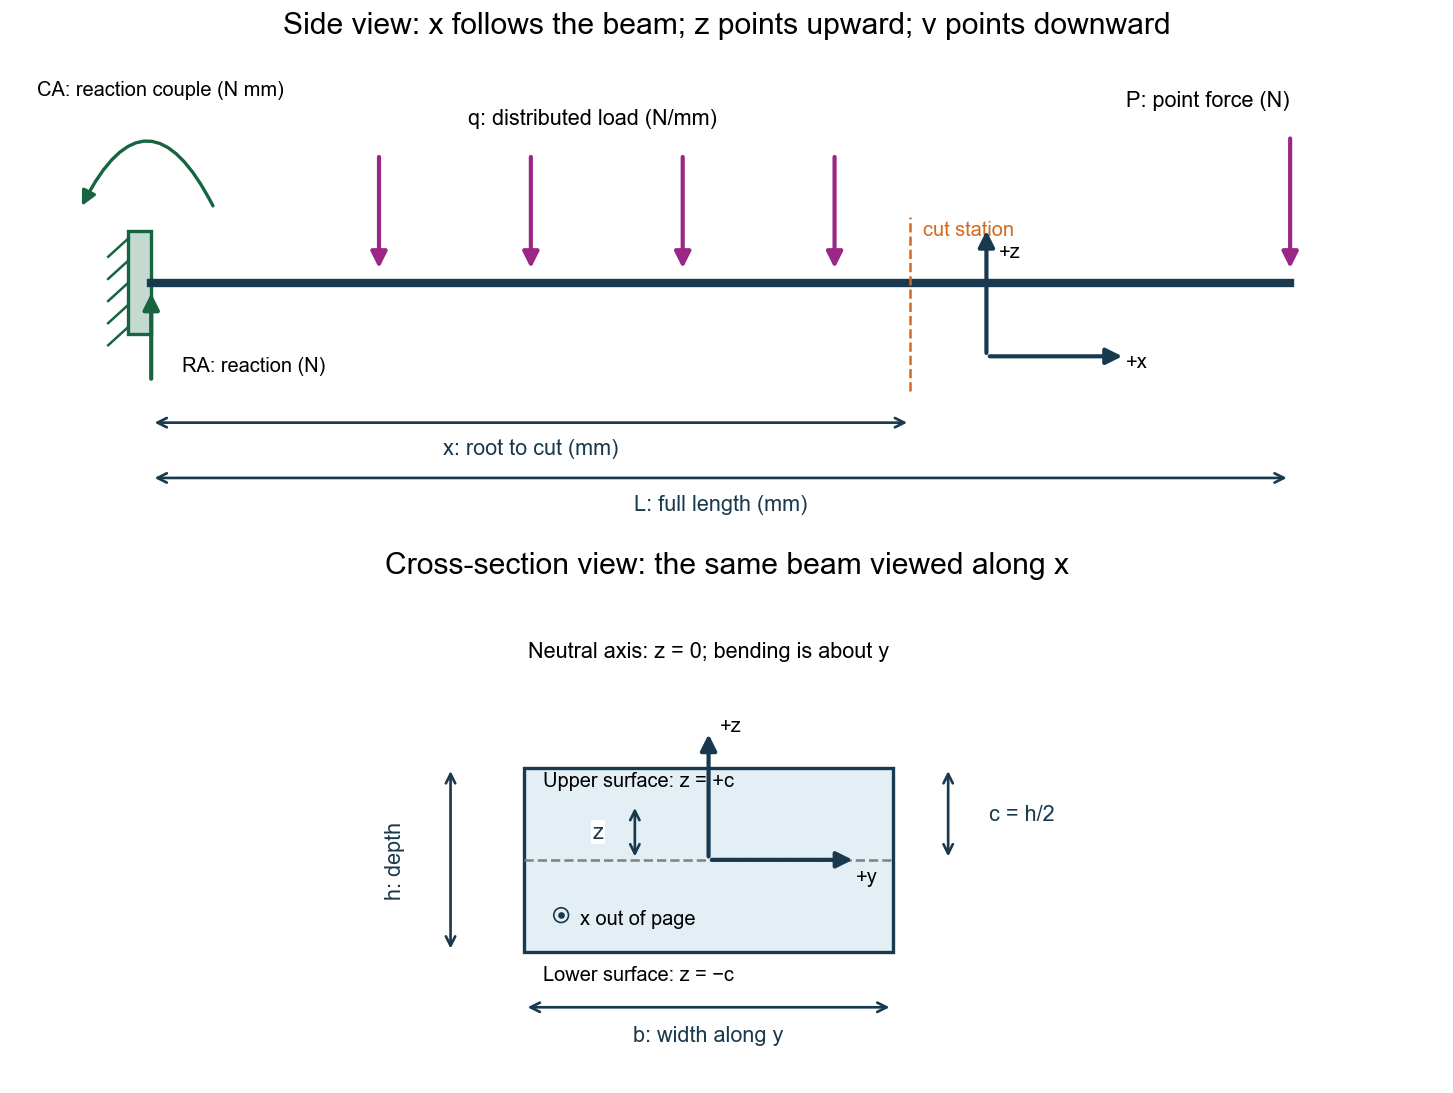

In [2]:
#@title Figure 0A — locate coordinates, section dimensions and load symbols
fig,axes=plt.subplots(2,1,figsize=(12,9),layout='constrained')
ax=axes[0]
clean_beam(ax,'Side view: x follows the beam; z points upward; v points downward')
support(ax,0,'fixed')
for at in [90,150,210,270]: arrow(ax,(at,35),(at,3))
ax.text(125,43,'q: distributed load (N/mm)',fontsize=13)
arrow(ax,(L,40),(L,3));ax.text(385,48,'P: point force (N)',fontsize=13)
arrow(ax,(0,-27),(0,-2),'#176441');ax.text(12,-24,'RA: reaction (N)',fontsize=12)
ax.add_patch(FancyArrowPatch((25,20),(-28,20),connectionstyle='arc3,rad=1',
                            arrowstyle='-|>',mutation_scale=18,color='#176441',lw=2))
ax.text(-45,51,'CA: reaction couple (N mm)',fontsize=12)
ax.axvline(300,ymin=.3,ymax=.65,color='#d46a1f',ls='--')
ax.text(305,13,'cut station',fontsize=12,color='#d46a1f')
dimension(ax,(0,-38),(300,-38),'x: root to cut (mm)',(0,-7))
dimension(ax,(0,-53),(L,-53),'L: full length (mm)',(0,-7))
arrow(ax,(330,-20),(385,-20),'#19394e');ax.text(385,-23,'+x',fontsize=12)
arrow(ax,(330,-20),(330,15),'#19394e');ax.text(335,7,'+z',fontsize=12)
ax.set_ylim(-70,65)
ax=axes[1]
ax.add_patch(Rectangle((-10,-5),20,10,facecolor='#e3eef5',edgecolor='#19394e',lw=2))
ax.plot([-10,10],[0,0],'--',color='gray')
dimension(ax,(-10,-8),(10,-8),'b: width along y',(0,-1.5))
dimension(ax,(-14,-5),(-14,5),'h: depth',(-3,0),rotation=90)
dimension(ax,(13,0),(13,5),'c = h/2',(4,0))
dimension(ax,(-4,0),(-4,3),'z',(-2,0))
arrow(ax,(0,0),(0,7),'#19394e');ax.text(.6,7,'+z',fontsize=12)
arrow(ax,(0,0),(8,0),'#19394e');ax.text(8,-1.2,'+y',fontsize=12)
ax.add_patch(Circle((-8,-3),.4,fill=False,color='#19394e'));ax.plot(-8,-3,'.',color='#19394e')
ax.text(-7,-3.5,'x out of page',fontsize=12)
ax.text(-9,4,'Upper surface: z = +c',fontsize=12)
ax.text(-9,-6.5,'Lower surface: z = −c',fontsize=12)
ax.text(0,11,'Neutral axis: z = 0; bending is about y',ha='center',fontsize=13)
ax.set(xlim=(-22,24),ylim=(-12,15),title='Cross-section view: the same beam viewed along x')
ax.set_aspect('equal');ax.axis('off')
plt.show()

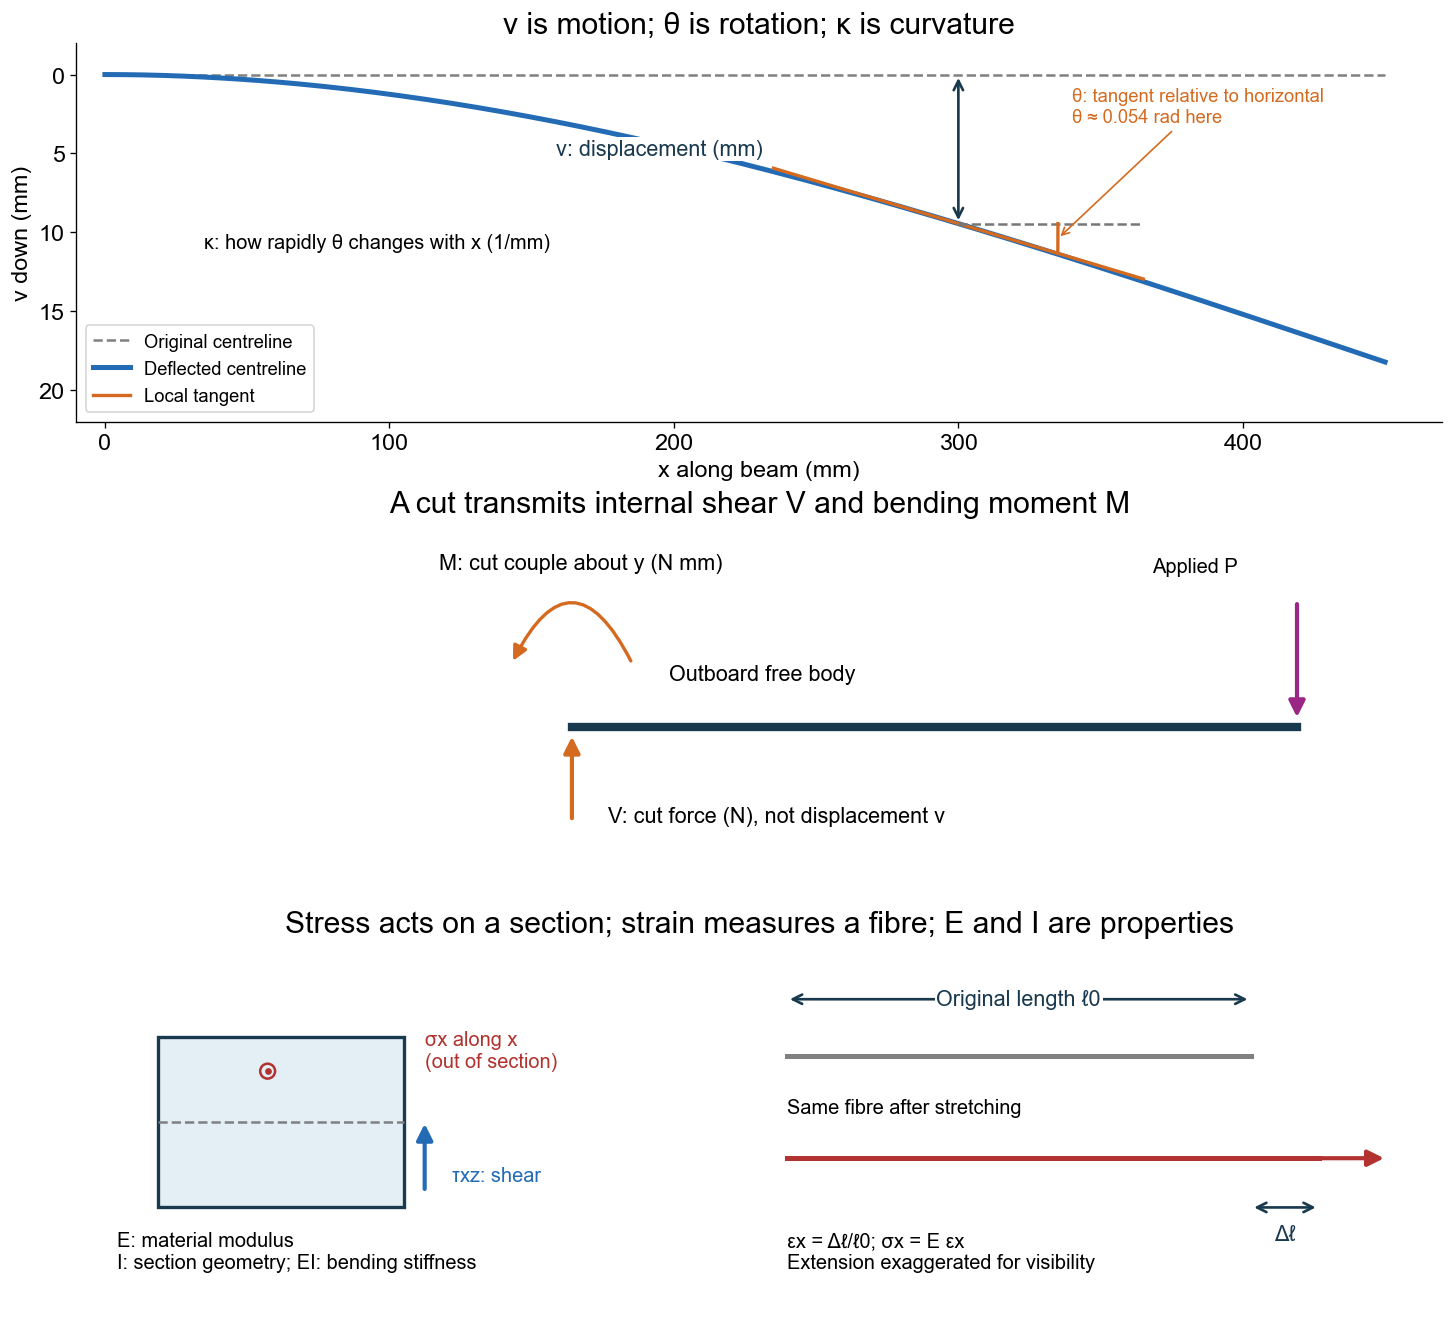

In [3]:
#@title Figure 0B — motion, internal actions and stress are different quantities
fig,axes=plt.subplots(3,1,figsize=(12,11),layout='constrained')
ax=axes[0]
xs=np.linspace(0,L,200); motion=P*xs**2*(3*L-xs)/(6*EI)
ax.plot(xs,np.zeros_like(xs),'--',color='gray',label='Original centreline')
ax.plot(xs,motion,color='#236bb4',lw=3,label='Deflected centreline')
at=300.; vt=P*at**2*(3*L-at)/(6*EI); slope=P*at*(2*L-at)/(2*EI)
ax.plot([at-65,at+65],[vt-65*slope,vt+65*slope],color='#d46a1f',lw=2,label='Local tangent')
ax.plot([at,at+65],[vt,vt],'--',color='#777777',lw=1.5)
aa=np.linspace(0,np.arctan(slope),50)
ax.plot(at+35*np.cos(aa),vt+35*np.sin(aa),color='#d46a1f',lw=2)
dimension(ax,(at,0),(at,vt),'v: displacement (mm)',(-105,0))
ax.annotate('θ: tangent relative to horizontal\nθ ≈ 0.054 rad here',
            xy=(at+35,vt+.95),xytext=(340,3),fontsize=11,color='#d46a1f',
            arrowprops=dict(arrowstyle='->',color='#d46a1f'))
ax.text(35,11,'κ: how rapidly θ changes with x (1/mm)',fontsize=12)
ax.set(xlim=(-10,470),ylim=(-2,22),title='v is motion; θ is rotation; κ is curvature')
ax.invert_yaxis();ax.set_xlabel('x along beam (mm)');ax.set_ylabel('v down (mm)');ax.legend(fontsize=11,loc='lower left')
ax=axes[1]
clean_beam(ax,'A cut transmits internal shear V and bending moment M')
ax.lines[0].remove();ax.plot([150,L],[0,0],lw=5,color='#19394e')
arrow(ax,(150,-30),(150,-2),'#d46a1f')
ax.text(165,-30,'V: cut force (N), not displacement v',fontsize=13)
ax.add_patch(FancyArrowPatch((175,20),(125,20),connectionstyle='arc3,rad=1',
                            arrowstyle='-|>',mutation_scale=18,color='#d46a1f',lw=2))
ax.text(95,50,'M: cut couple about y (N mm)',fontsize=13)
arrow(ax,(L,40),(L,2));ax.text(390,49,'Applied P',fontsize=12)
ax.text(190,15,'Outboard free body',fontsize=13)
ax=axes[2];ax.set(xlim=(0,1),ylim=(0,1));ax.axis('off')
ax.set_title('Stress acts on a section; strain measures a fibre; E and I are properties')
ax.add_patch(Rectangle((.06,.30),.18,.45,facecolor='#e3eef5',edgecolor='#19394e',lw=2))
ax.plot([.06,.24],[.525,.525],'--',color='gray')
ax.scatter([.14],[.66],s=80,facecolors='none',edgecolors='#b1322e',linewidths=1.5)
ax.plot(.14,.66,'.',color='#b1322e')
ax.text(.255,.67,'σx along x\n(out of section)',fontsize=12,color='#b1322e')
arrow(ax,(.255,.34),(.255,.53),'#236bb4')
ax.text(.275,.37,'τxz: shear',fontsize=12,color='#236bb4')
ax.text(.03,.14,'E: material modulus\nI: section geometry; EI: bending stiffness',fontsize=12)
ax.plot([.52,.86],[.70,.70],color='gray',lw=3)
ax.plot([.52,.91],[.43,.43],color='#b1322e',lw=3)
dimension(ax,(.52,.85),(.86,.85),'Original length ℓ0')
dimension(ax,(.86,.30),(.91,.30),'Δℓ',(0,-.07))
arrow(ax,(.91,.43),(.96,.43),'#b1322e')
ax.text(.52,.55,'Same fibre after stretching',fontsize=12)
ax.text(.52,.14,'εx = Δℓ/ℓ0; σx = E εx\nExtension exaggerated for visibility',fontsize=12)
plt.show()

## 1. What a support prevents and what it can transmit

A reaction is the force or moment that a support exerts to enforce a restricted motion. Do not draw a reaction moment at an ideal pin or roller: these allow rotation. A fixed support restricts rotation as well as translation.

| Ideal support in a planar model | Prevented motion | Reaction unknowns | Motion still allowed |
|---|---|---|---|
| Pin | Horizontal and vertical translation | R_x,R_z | Rotation |
| Roller on a horizontal surface | Vertical translation | R_z | Horizontal translation and rotation |
| Fixed clamp | Both translations and rotation | R_x,R_z,M_A | None at the support |
| Free end | None | No support reaction | Translation and rotation |

These are idealizations, not descriptions of every bolt or bearing. A real wing attachment uses multiple fittings to transmit forces and a couple. In our **transverse-bending app**, only displacement v and slope θ are solved: axial displacement is not a degree of freedom. Under purely transverse loading the planar horizontal reaction is zero, not an additional solved app result.

For a whole planar free body:

$$\sum F_x=0,\qquad \sum F_z=0,\qquad \sum M=0.$$

A pin–roller beam has three planar reaction unknowns and three equilibrium equations. Two fixed ends have six planar unknowns: equilibrium alone is insufficient. In transverse bending, four reactions (R_A,M_A,R_B,M_B) need two equilibrium equations **plus displacement/rotation compatibility and stiffness**. Here no axial load is applied; the separate axial redundancy is outside the transverse model.

**How to draw a reaction:** imagine the support removed, leaving only the beam. Replace each motion that was prevented by a possible force or couple. Initially assume a direction; a negative solution means the real direction is opposite. The fixed support requires a couple because it prevents the end section rotating. A pin lets that section rotate, so an ideal pin has no reaction couple.

For our transverse cantilever, two nonzero reaction unknowns are enough: the vertical root force and the root couple. Taking moments about the root removes the root force from that equation because its lever arm is zero. For a pin–roller beam, taking moments about A first determines the reaction at B; vertical equilibrium then determines A.

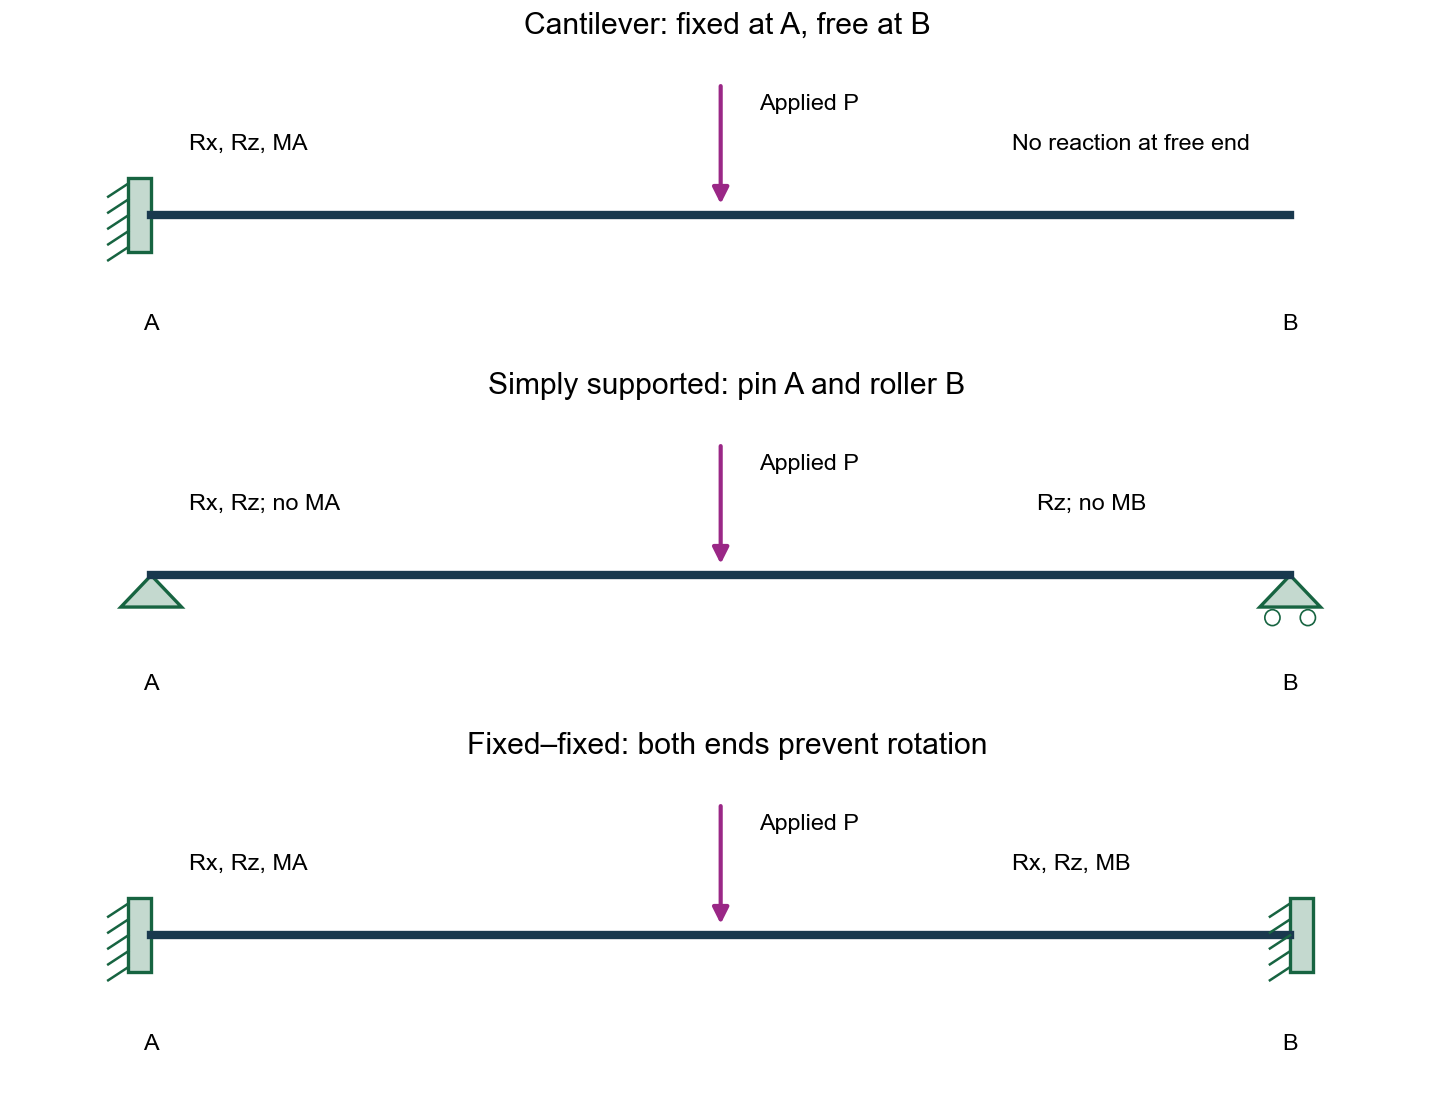

In [4]:
#@title Figure 1 — supports, permitted motions and reaction unknowns
fig, axes = plt.subplots(3,1,figsize=(12,9),layout='constrained')
for ax, title in zip(axes,['Cantilever: fixed at A, free at B',
                         'Simply supported: pin A and roller B',
                         'Fixed–fixed: both ends prevent rotation']):
    clean_beam(ax,title)
support(axes[0],0,'fixed')
support(axes[1],0,'pin'); support(axes[1],L,'roller')
support(axes[2],0,'fixed'); support(axes[2],L+9,'fixed')
for ax in axes:
    arrow(ax,(225,50),(225,3)); ax.text(240,40,'Applied P')
    ax.text(0,-43,'A',ha='center'); ax.text(L,-43,'B',ha='center')
axes[0].text(15,25,'Rx, Rz, MA'); axes[0].text(340,25,'No reaction at free end')
axes[1].text(15,25,'Rx, Rz; no MA'); axes[1].text(350,25,'Rz; no MB')
axes[2].text(15,25,'Rx, Rz, MA'); axes[2].text(340,25,'Rx, Rz, MB')
plt.show()

### Boundary conditions are not reactions

For small deflections, slope is rotation:

$$\theta(x)=\frac{dv}{dx}.$$

Fixed end: v=0,θ=0. Simple support: v=0, rotation is free and the end bending moment is zero when no applied end couple is present. Unloaded free end: V=0,M=0. **A loaded free end is not force-free:** a tip force changes the shear boundary condition.

**Prediction:** can a point force placed exactly on a simple support bend the span? It can be taken directly by the support. For comparisons below the force is at midspan, not on a support.

## 2. Example A — a wing-like cantilever with a tip test load

Our rectangular PLA-like strip is a **teaching surrogate**, not the actual airfoil/wing box. Use L=450 mm, b=20 mm, vertical depth h=10 mm and assumed E=2000 MPa. Apply P=2 N downward at the free tip. Neglect self-weight; no load factor or extra weight is added automatically.

**Before calculating:** sketch the direction of the root force and root couple. Where should the largest displacement and largest moment occur?

Using upward-positive forces and counterclockwise-positive moments for this hand free body:

$$R_A-P=0,\qquad C_A-PL=0.$$

$$R_A=2\ \mathrm{N\ upward},\qquad C_A=900\ \mathrm{N\,mm\ counterclockwise}.$$

The **app** reports support force positive downward and support couple positive clockwise, so its reactions are **−2 N and −900 N mm**. These represent the same physical reactions. The reaction couple (C_A) is not the internal bending-moment sign at a section.

**Read these as physical constraints:** v(0) = 0 means the root point cannot translate vertically; θ(0) = 0 means the root tangent cannot rotate. They do not say that the reaction force or bending moment is zero. A simple support fixes v but not θ. At an unloaded free end, it is the force resultants V and M that vanish.

The shape is solved with four boundary conditions because its governing equation is fourth order. At a tip carrying P, the free-end moment is still zero (no applied tip couple), but shear just inside the tip is P. This distinction will be labelled on the deflected shape.

[Open and solve Example A — 2 N tip load](https://ehsan-roohi.github.io/Aerospace-Structures/wing-lab.html?beamCase=l03-tip)

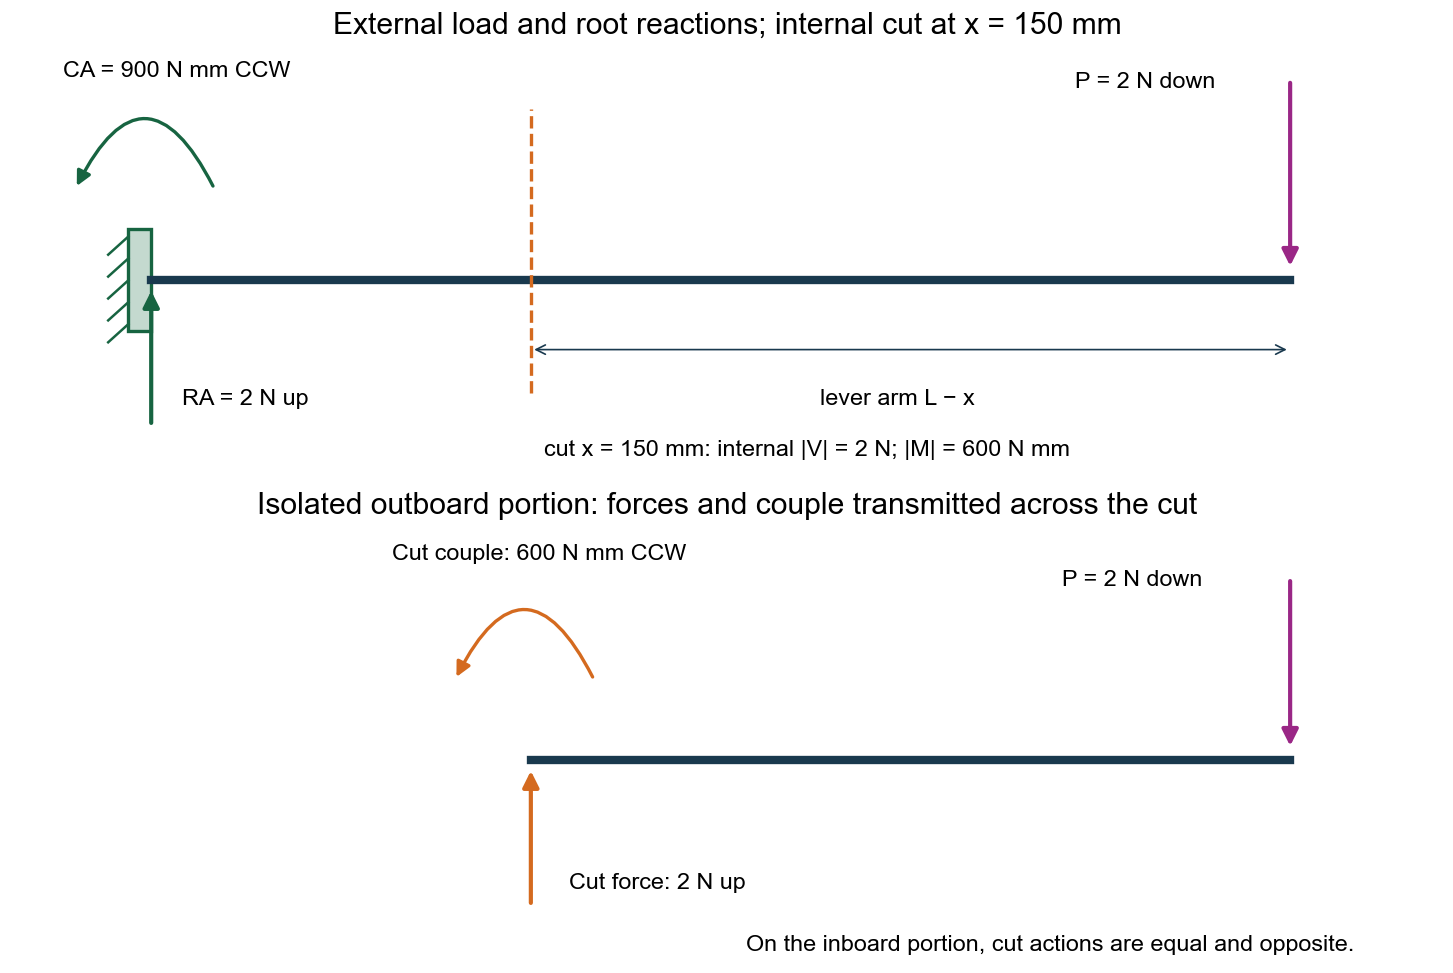

In [5]:
#@title Figure 2 — external free body and an outboard cut
fig, panels = plt.subplots(2,1,figsize=(12,8),layout='constrained')
ax=panels[0]
clean_beam(ax,'External load and root reactions; internal cut at x = 150 mm')
support(ax,0,'fixed')
arrow(ax,(L,55),(L,3)); ax.text(365,53,'P = 2 N down')
arrow(ax,(0,-40),(0,-2),'#176441'); ax.text(12,-34,'RA = 2 N up')
ax.add_patch(FancyArrowPatch((25,25),(-30,25),connectionstyle='arc3,rad=1',arrowstyle='-|>',mutation_scale=18,color='#176441',lw=2))
ax.text(-35,56,'CA = 900 N mm CCW')
ax.axvline(150,ymin=.2,ymax=.85,color='#d46a1f',ls='--',lw=2)
ax.text(155,-48,'cut x = 150 mm: internal |V| = 2 N; |M| = 600 N mm')
ax.annotate('',xy=(L,-19),xytext=(150,-19),arrowprops={'arrowstyle':'<->','color':'#19394e'})
ax.text(295,-34,'lever arm L − x',ha='center')
ax=panels[1]
clean_beam(ax,'Isolated outboard portion: forces and couple transmitted across the cut')
ax.lines[0].remove()
ax.plot([150,L],[0,0],color='#19394e',lw=5)
arrow(ax,(L,50),(L,3)); ax.text(360,48,'P = 2 N down')
arrow(ax,(150,-40),(150,-2),'#d46a1f'); ax.text(165,-35,'Cut force: 2 N up')
ax.add_patch(FancyArrowPatch((175,22),(120,22),connectionstyle='arc3,rad=1',arrowstyle='-|>',mutation_scale=18,color='#d46a1f',lw=2))
ax.text(95,55,'Cut couple: 600 N mm CCW')
ax.text(235,-52,'On the inboard portion, cut actions are equal and opposite.')
plt.show()

## 3. A cut reveals the internal shear and moment

Isolate the portion to the right of a cut at x. The tip force still acts on it. The cut must supply a shear force and bending moment to balance that portion. **Internal forces are not additional applied loads:** on opposite cut faces they form equal-and-opposite pairs.

Use the app convention throughout the following diagrams: downward load q and deflection v positive; positive internal M is sagging; z positive upward from the neutral axis.

$$V(x)=P,\qquad M(x)=-P(L-x),\qquad 0<x<L.$$

At (x=150) mm, (V=2) N and (M=-600) N mm. At the root-side section, M=-900 N mm. At the tip, (M=0). Shear has a jump at a point force; do not interpret a vertical jump as a finite-length triangular load.

For a distributed downward-positive load:

$$\frac{dV}{dx}=-q(x),\qquad \frac{dM}{dx}=V(x).$$

In words: load changes the shear; shear changes the moment. A constant shear produces a straight-line moment diagram.

### Calculate at a cut rather than memorize a diagram

At x = 150 mm the outboard portion is 300 mm long. Its 2 N tip load produces a 600 N mm clockwise external turning effect about the cut. The cut therefore supplies 2 N upward and a 600 N mm counterclockwise couple to that outboard portion. These are the physical arrows in Figure 2. With the app's internal sagging-positive convention, the reported section values are V = +2 N and M = −600 N mm.

| Cut station x | Remaining lever arm L − x | V | M = −P(L − x) |
|---:|---:|---:|---:|
| 0 mm, just inside the root | 450 mm | +2 N | −900 N mm |
| 150 mm | 300 mm | +2 N | −600 N mm |
| 300 mm | 150 mm | +2 N | −300 N mm |
| 450 mm, just inside the tip | 0 mm | +2 N | 0 N mm |

The derivative relations are local equilibrium statements. Over a short distance Δx, downward distributed load qΔx decreases V by approximately qΔx. Moment changes by approximately VΔx. Therefore a uniform q gives a linear V diagram and a curved, quadratic M diagram; with no line load between root and tip, V is constant.

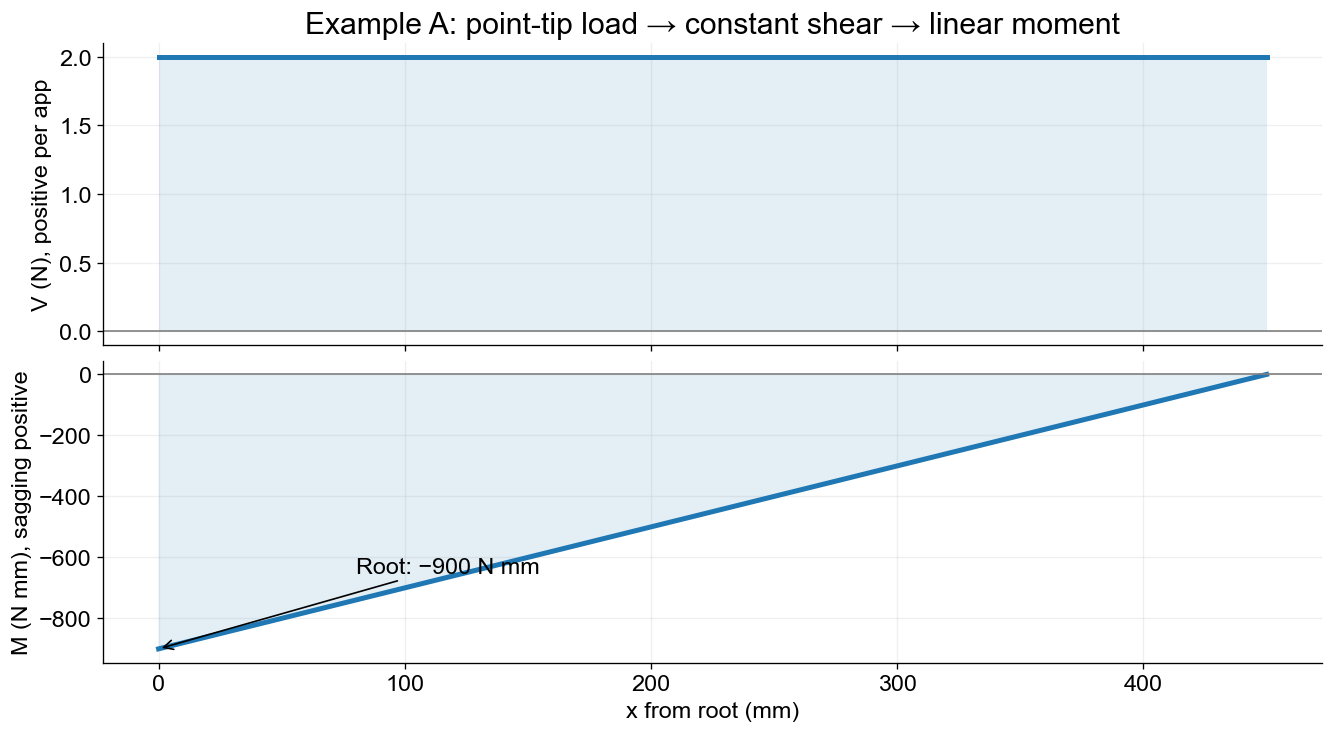

In [6]:
#@title Figure 3 — shear and moment along the cantilever
V = np.full_like(x,P)
M = -P*(L-x)
fig, axes = plt.subplots(2,1,figsize=(11,6),layout='constrained',sharex=True)
for ax,y,label in zip(axes,[V,M],['V (N), positive per app','M (N mm), sagging positive']):
    ax.plot(x,y,lw=3); ax.fill_between(x,y,0,alpha=.12); ax.axhline(0,color='gray',lw=1)
    ax.set_ylabel(label); ax.grid(alpha=.2)
axes[0].set_title('Example A: point-tip load → constant shear → linear moment')
axes[1].set_xlabel('x from root (mm)')
axes[1].annotate('Root: −900 N mm',xy=(0,-900),xytext=(80,-650),arrowprops={'arrowstyle':'->'})
plt.show()

## 4. From moment to bending stress

A bending moment produces longitudinal tension on one side and compression on the other. In a homogeneous beam the neutral axis passes through the section centroid; bending normal stress is zero there.

$$A=bh=200\ \mathrm{mm^2},\qquad I=\frac{bh^3}{12}=1666.67\ \mathrm{mm^4}.$$

$$\boxed{\sigma_x(x,z)=-\frac{M(x)z}{I}},\qquad
\boxed{|\sigma_{\max}|=\frac{|M|c}{I}},\qquad c=\frac{h}{2}.$$


Here I is the **second moment of area**, not mass moment of inertia. Its mm⁴ units make (N mm)(mm)/mm^4=N/mm^2. Stress is positive in tension. At the root under downward loading, M=-900: top z=+5 has +2.70 MPa tension; bottom has -2.70 MPa compression. **Upward wing lift reverses these signs:** top compression, bottom tension.

The formula is nominal beam stress away from local details. It does not resolve bolt holes, clamp contact or stress concentrations, and does not predict buckling. A fixed end can carry a large moment while its displacement remains zero.

### Shear stress is different from bending stress

For a solid rectangle, transverse shear stress is parabolic across the depth:

$$\tau_{xz}(z)=\frac{3V}{2A}\left[1-\left(\frac{2z}{h}\right)^2\right],\qquad
|\tau_{\max}|=\frac{3|V|}{2A}=0.015\ \mathrm{MPa}.$$

It is maximum at the neutral axis and zero at top/bottom surfaces. Do not combine this maximum shear with maximum bending as if they occur at the same location. For a wing box, caps/skins carry bending and webs/skins carry shear; the solid-rectangle shear formula is not a wing-web formula.

### How Figure 4 is actually calculated

Figure 4 is a **single section just inside the root**, not an entire spanwise stress map. First obtain its bending moment from the free-body calculation: M = −P L = −900 N mm. Then calculate I from the section dimensions. Finally choose a fibre height z and substitute into the stress equation. Width b lies along y; depth h lies along z; x comes out of the cross-section view. The neutral axis is z = 0, and the upper/lower surfaces are z = ±h/2.

The second moment of area weights each tiny area by the square of its distance from the neutral axis:

$$I_y=\int_A z^2\,dA=b\int_{-h/2}^{h/2}z^2\,dz=\frac{bh^3}{12}.$$

Here I means Iᵧ for bending about the transverse y-axis. The strip area dA = b dz is drawn in the geometry panel. Material farther from the neutral axis contributes more to I. A wider section increases I linearly; a deeper section increases it cubically.

For this root section the two plotted functions are:

$$\sigma_x(z)=-\frac{(-900)z}{1666.6667}=0.54z\quad\mathrm{MPa},$$

$$\tau_{xz}(z)=0.015\left[1-\left(\frac{z}{5}\right)^2\right]\quad\mathrm{MPa}.$$

| Fibre height z | Bending stress σₓ | Transverse shear τₓz | Interpretation |
|---:|---:|---:|---|
| +5 mm | +2.700 MPa | 0 | Top: tension in this downward-load example |
| +2.5 mm | +1.350 MPa | 0.01125 MPa | Both components present |
| 0 mm | 0 | 0.01500 MPa | Neutral axis: zero bending stress, maximum shear |
| −2.5 mm | −1.350 MPa | 0.01125 MPa | Compression and shear |
| −5 mm | −2.700 MPa | 0 | Bottom: compression |

The red curve joins these bending-stress values; its straight shape comes from proportionality to z. The blue curve joins the shear values; its parabolic shape comes from the squared z term. Their horizontal axes have different scales and units must be read, not compared by apparent curve width.

**Why the rectangular shear equation has this form:** for a solid rectangle the first moment of the area above a horizontal cut is Q = b[(h/2)² − z²]/2. The section shear relation gives τ = VQ/(Ib), which simplifies to the parabolic equation above. The b in its denominator is the local solid section width. This relation is not an instruction to substitute wing-skin thickness for b.

**Nominal stress check:** compare stress with a justified material allowable only after specifying the material, print direction, temperature and safety requirement. E describes stiffness, not failure strength. No allowable is supplied here, so this example does not claim the part is safe.

Calculation sequence: P and L → root M; b and h → I; selected z → stress.
I = 20 × 10³ / 12 = 1666.666667 mm⁴
z= -5.0 mm: σx=-2.70000 MPa; τxz=0.00000 MPa
z= -2.5 mm: σx=-1.35000 MPa; τxz=0.01125 MPa
z= +0.0 mm: σx=+0.00000 MPa; τxz=0.01500 MPa
z= +2.5 mm: σx=+1.35000 MPa; τxz=0.01125 MPa
z= +5.0 mm: σx=+2.70000 MPa; τxz=0.00000 MPa


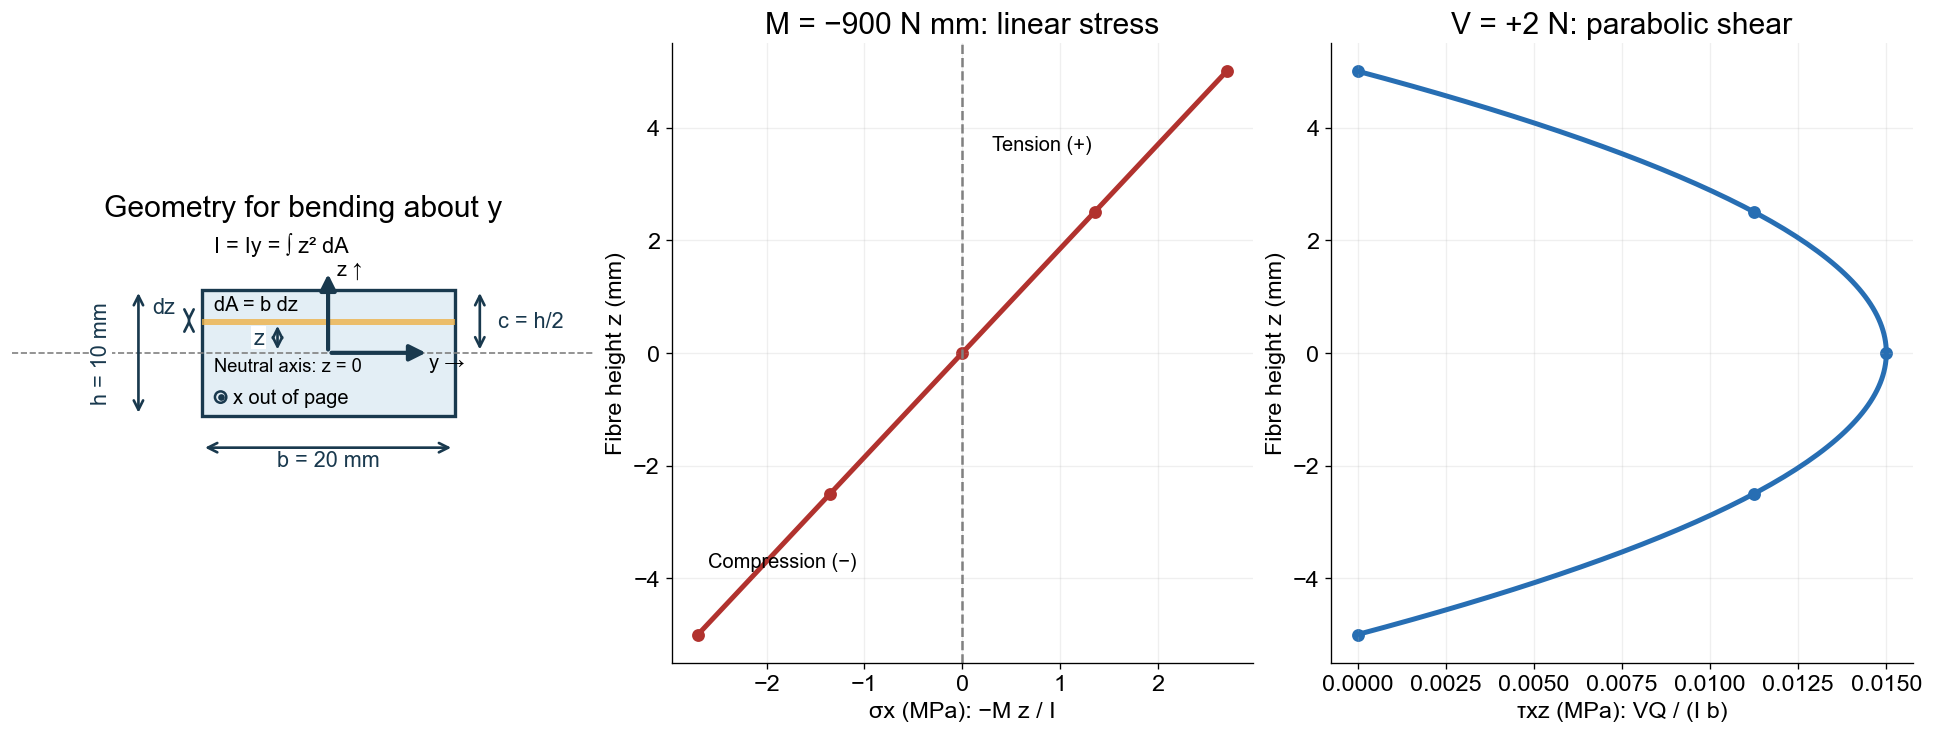

In [7]:

#@title Figure 4 — dimensions, area strip, numerical stress samples and profiles
z=np.linspace(-h/2,h/2,151)
sigma=-(-P*L)*z/I
tau=1.5*P/A*(1-(2*z/h)**2)
fig,axes=plt.subplots(1,3,figsize=(16,6),layout='constrained')
ax=axes[0]
ax.add_patch(Rectangle((-b/2,-h/2),b,h,facecolor='#e3eef5',edgecolor='#19394e',lw=2))
ax.add_patch(Rectangle((-b/2,2.2),b,.45,facecolor='#eeb147',alpha=.8))
ax.axhline(0,color='gray',ls='--',lw=1)
dimension(ax,(-10,-7.5),(10,-7.5),'b = 20 mm',(0,-1))
dimension(ax,(-15,-5),(-15,5),'h = 10 mm',(-3,0),rotation=90)
dimension(ax,(12,0),(12,5),'c = h/2',(4,0))
dimension(ax,(-4,0),(-4,2.4),'z',(-1.5,0))
dimension(ax,(-11,2.2),(-11,2.65),'dz',(-2,1.2))
ax.text(-9,3.4,'dA = b dz',fontsize=12)
arrow(ax,(0,0),(0,6.5),'#19394e'); ax.text(.7,6.2,'z ↑',fontsize=12)
arrow(ax,(0,0),(8,0),'#19394e'); ax.text(8,-1.2,'y →',fontsize=12)
ax.text(-9,-1.4,'Neutral axis: z = 0',fontsize=11)
ax.add_patch(Circle((-8.5,-3.5),.45,fill=False,edgecolor='#19394e',lw=1.5))
ax.plot(-8.5,-3.5,'.',color='#19394e')
ax.text(-7.5,-4,'x out of page',fontsize=12)
ax.text(-9,8,'I = Iy = ∫ z² dA',fontsize=13)
ax.set(xlim=(-25,21),ylim=(-10,10),title='Geometry for bending about y')
ax.set_aspect('equal'); ax.axis('off')
samples=np.array([-5,-2.5,0,2.5,5])
axes[1].plot(sigma,z,lw=3,color='#b1322e')
axes[1].scatter(.54*samples,samples,s=45,color='#b1322e')
axes[1].axvline(0,color='gray',ls='--')
axes[1].set(xlabel='σx (MPa): −M z / I',ylabel='Fibre height z (mm)',title='M = −900 N mm: linear stress')
axes[1].text(-2.6,-3.8,'Compression (−)',fontsize=12)
axes[1].text(.3,3.6,'Tension (+)',fontsize=12)
axes[2].plot(tau,z,lw=3,color='#276eb3')
axes[2].scatter(.015*(1-(samples/5)**2),samples,s=45,color='#276eb3')
axes[2].set(xlabel='τxz (MPa): VQ / (I b)',ylabel='Fibre height z (mm)',title='V = +2 N: parabolic shear')
for ax in axes[1:]: ax.grid(alpha=.2)
plt.show()
print('Calculation sequence: P and L → root M; b and h → I; selected z → stress.')
print(f'I = {b:g} × {h:g}³ / 12 = {I:.6f} mm⁴')
for zi in samples:
    print(f'z={zi:+5.1f} mm: σx={P*L*zi/I:+.5f} MPa; τxz={1.5*P/A*(1-(2*zi/h)**2):.5f} MPa')


### Figure 4B — locate Q before using the shear equation

At the chosen height z = +2.5 mm, select the **whole area above that cut**, not a thin strip and not the entire rectangle. Its area is 50 mm² and its centroid is 3.75 mm above the neutral axis. Thus Q = 50 × 3.75 = 187.5 mm³. This Q is a **first moment of area**; I is a second moment of area. They have different meanings and units.

$$\tau_{xz}(2.5)=\frac{(2)(187.5)}{(1666.6667)(20)}
=0.01125\ \mathrm{MPa}.$$

At the top surface there is no area above the cut and Q = 0, so transverse shear is zero. At the neutral axis the selected area is the upper half and Q = 250 mm³, giving the maximum 0.015 MPa. The blue stress profile in Figure 4 comes from repeating this calculation at different heights.

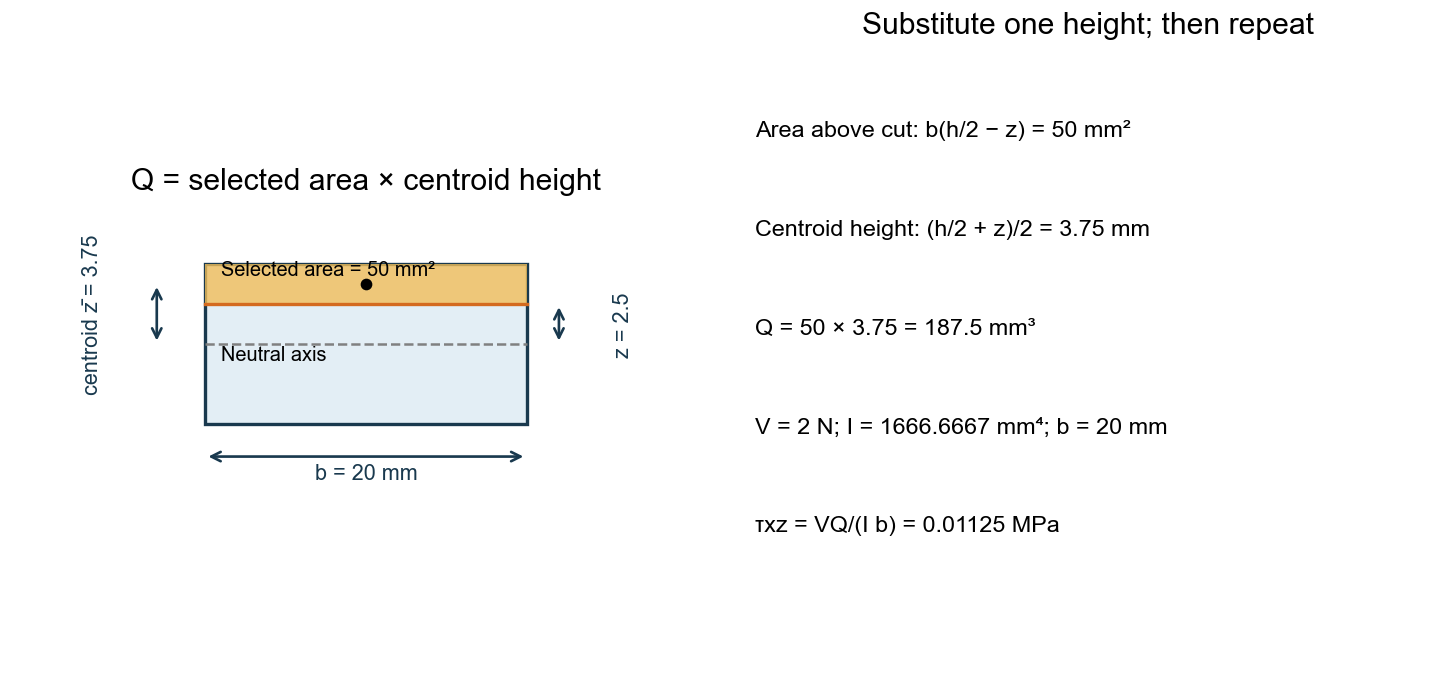

In [8]:
#@title Figure 4B — first moment Q uses the area above a chosen cut
fig,axes=plt.subplots(1,2,figsize=(12,5.5),layout='constrained')
ax=axes[0]; chosen_z=2.5
ax.add_patch(Rectangle((-10,-5),20,10,facecolor='#e3eef5',edgecolor='#19394e',lw=2))
ax.add_patch(Rectangle((-10,chosen_z),20,5-chosen_z,facecolor='#f1be5a',alpha=.8))
ax.plot([-10,10],[chosen_z,chosen_z],color='#d46a1f',lw=2)
ax.plot([-10,10],[0,0],'--',color='gray')
ax.plot(0,3.75,'ko')
ax.text(-9,4.3,'Selected area = 50 mm²',fontsize=12)
ax.text(-9,-1,'Neutral axis',fontsize=12)
dimension(ax,(12,0),(12,chosen_z),'z = 2.5',(4,0),rotation=90)
dimension(ax,(-13,0),(-13,3.75),'centroid z̄ = 3.75',(-4,0),rotation=90)
dimension(ax,(-10,-7),(10,-7),'b = 20 mm',(0,-1))
ax.set(xlim=(-22,22),ylim=(-10,9),title='Q = selected area × centroid height')
ax.set_aspect('equal');ax.axis('off')
ax=axes[1];ax.axis('off')
lines=['Area above cut: b(h/2 − z) = 50 mm²',
       'Centroid height: (h/2 + z)/2 = 3.75 mm',
       'Q = 50 × 3.75 = 187.5 mm³',
       'V = 2 N; I = 1666.6667 mm⁴; b = 20 mm',
       'τxz = VQ/(I b) = 0.01125 MPa']
for j,line in enumerate(lines):
    ax.text(.03,.85-j*.16,line,transform=ax.transAxes,fontsize=14)
ax.set_title('Substitute one height; then repeat')
plt.show()


## 5. Why bending creates strain and how curvature creates displacement

### Start with the definition of strain

Longitudinal strain εₓ is the change in a material fibre's length divided by its original length. It is dimensionless. A strain of 0.00135 means a 0.135% change in length, not a 0.00135 mm displacement:

$$\varepsilon_x=\frac{\ell-\ell_0}{\ell_0}=\frac{\Delta\ell}{\ell_0}.$$

In the elementary bending model, cross-sections remain plane and perpendicular to the neutral fibre. Adjacent sections rotate relative to each other. With no net axial extension, the neutral fibre keeps its length; fibres farther from it lengthen or shorten more.

### Read the arc geometry in the next figure

The neutral fibre follows a small arc of radius R and angle Δφ. Its length is RΔφ. For the downward-curving case drawn, the top fibre at positive z is farther from the centre of curvature and has length (R + z)Δφ. Subtracting the neutral-fibre length gives:

$$\varepsilon_x=\frac{(R+z)\Delta\phi-R\Delta\phi}{R\Delta\phi}
=\frac{z}{R}=z\kappa.$$

Here R is a curvature radius, **not a support reaction**. The bottom fibre has negative z and therefore negative strain. This sign statement is tied to our drawn positive, downward curvature; reversing the load reverses the curvature and the tension/compression sides.

### Connect the geometry to the beam's displacement

With v positive downward, the exact signed curvature of the centreline graph is:

$$\kappa=\frac{v''}{[1+(v')^2]^{3/2}}\approx v''\qquad\text{for small slopes}.$$

Linear elastic material obeys Hooke's law σₓ = E εₓ. The signed sagging-positive moment is the moment of the longitudinal stress distribution:

$$M=-\int_A z\sigma_x\,dA=-E\kappa\int_A z^2\,dA=-EI\kappa.$$

The minus sign belongs to the chosen sagging-positive M and downward-positive v conventions. This chain gives both relations rather than introducing them as unrelated formulas:

$$\boxed{\varepsilon_x=zv''},\qquad
\boxed{\sigma_x=E\varepsilon_x=-\frac{Mz}{I}},\qquad
\boxed{v''=-\frac{M}{EI}}.$$

At the root of Example A, κ = 900/3,333,333.33 = 0.000270 mm⁻¹. At z = +5 mm, εₓ = 0.001350 and σₓ = 2000 × 0.001350 = 2.700 MPa. That is the top point of Figure 4. The curvature relation is an approximation to beam geometry, not a new applied load.


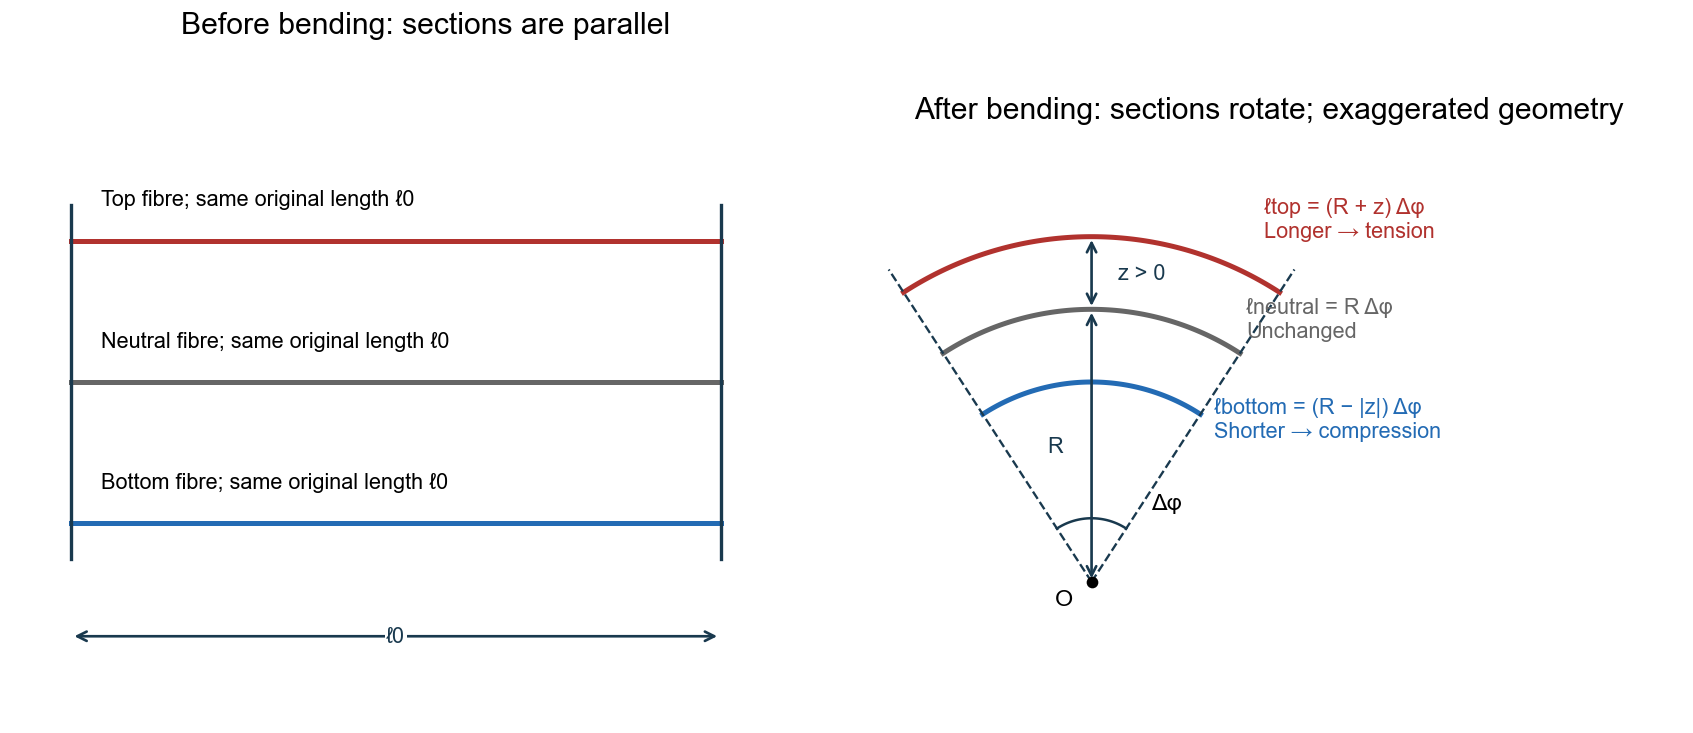

In [9]:
#@title Figure 5A — equal original fibres become different-length arcs
fig,axes=plt.subplots(1,2,figsize=(14,6),layout='constrained')
ax=axes[0]
for zz,col,name in [(20,'#b1322e','Top fibre'),(0,'#666666','Neutral fibre'),(-20,'#236bb4','Bottom fibre')]:
    ax.plot([0,110],[zz,zz],color=col,lw=3)
    ax.text(5,zz+5,name+'; same original length ℓ0',fontsize=13)
for xx in [0,110]: ax.plot([xx,xx],[-25,25],color='#19394e',lw=2)
dimension(ax,(0,-36),(110,-36),'ℓ0')
ax.set(xlim=(-10,130),ylim=(-48,48),title='Before bending: sections are parallel')
ax.axis('off')
ax=axes[1]
Rdemo=60.; zdemo=16.
ang=np.linspace(np.deg2rad(57),np.deg2rad(123),100)
for rad,col,label in [(Rdemo+zdemo,'#b1322e','Top: (R + z) Δφ'),(Rdemo,'#666666','Neutral: R Δφ'),(Rdemo-zdemo,'#236bb4','Bottom: (R − |z|) Δφ')]:
    ax.plot(rad*np.cos(ang),rad*np.sin(ang),color=col,lw=3)
for a in [ang[0],ang[-1]]:
    ax.plot([0,82*np.cos(a)],[0,82*np.sin(a)],color='#19394e',lw=1.4,ls='--')
ax.plot(0,0,'ko'); ax.text(-8,-5,'O',fontsize=14)
dimension(ax,(0,0),(0,Rdemo),'R',(-8,0))
dimension(ax,(0,Rdemo),(0,Rdemo+zdemo),'z > 0',(11,0))
ax.plot(14*np.cos(ang),14*np.sin(ang),color='#19394e')
ax.text(13,16,'Δφ',fontsize=14)
ax.text(38,76,'ℓtop = (R + z) Δφ\nLonger → tension',fontsize=13,color='#b1322e')
ax.text(34,54,'ℓneutral = R Δφ\nUnchanged',fontsize=13,color='#666666')
ax.text(27,32,'ℓbottom = (R − |z|) Δφ\nShorter → compression',fontsize=13,color='#236bb4')
ax.set(xlim=(-52,130),ylim=(-12,100),title='After bending: sections rotate; exaggerated geometry')
ax.set_aspect('equal'); ax.axis('off')
plt.show()

### Integrate curvature using the physical root constraints

For Example A the cut already gave M(x) = −P(L − x). Divide by EI to obtain curvature. Integrate along x to obtain rotation, then displacement:

$$v''=\frac{P(L-x)}{EI},$$

$$\theta=v'=\frac{P}{EI}\left(Lx-\frac{x^2}{2}\right)+C_1,$$

$$v=\frac{P}{EI}\left(\frac{Lx^2}{2}-\frac{x^3}{6}\right)+C_1x+C_2.$$

The fixed root gives θ(0) = 0, so C₁ = 0; it also gives v(0) = 0, so C₂ = 0. These constraints, labelled on Figure 5B, produce:

$$\theta(x)=\frac{Px(2L-x)}{2EI},\qquad
v(x)=\frac{Px^2(3L-x)}{6EI}.$$

At the tip, substitute x = L:

$$\boxed{v(L)=\frac{PL^3}{3EI}
=\frac{2(450)^3}{3(2000)(1666.6667)}
=18.225\ \mathrm{mm}}.$$

| Station | Curvature κ | Rotation θ | Displacement v |
|---|---:|---:|---:|
| Root x = 0 | 0.000270 mm⁻¹ | 0 rad | 0 mm |
| Cut x = 150 mm | 0.000180 mm⁻¹ | 0.033750 rad | 2.700 mm |
| Tip x = 450 mm | 0 mm⁻¹ | 0.060750 rad | 18.225 mm |

The root can have nonzero curvature and strain despite zero displacement and slope. At the tip, zero moment/curvature does not imply zero accumulated rotation or displacement. Integration carries the bending effect of the whole inboard span into the tip motion. The tip slope is about 3.48°, and deflection is about 4.05% of span; check the small-deflection approximation for a real test. This solid strip is not the actual airfoil-section wing.

Tip deflection = 18.2250 mm; root deflection = 0.0000 mm
Tip slope = 0.06075 rad


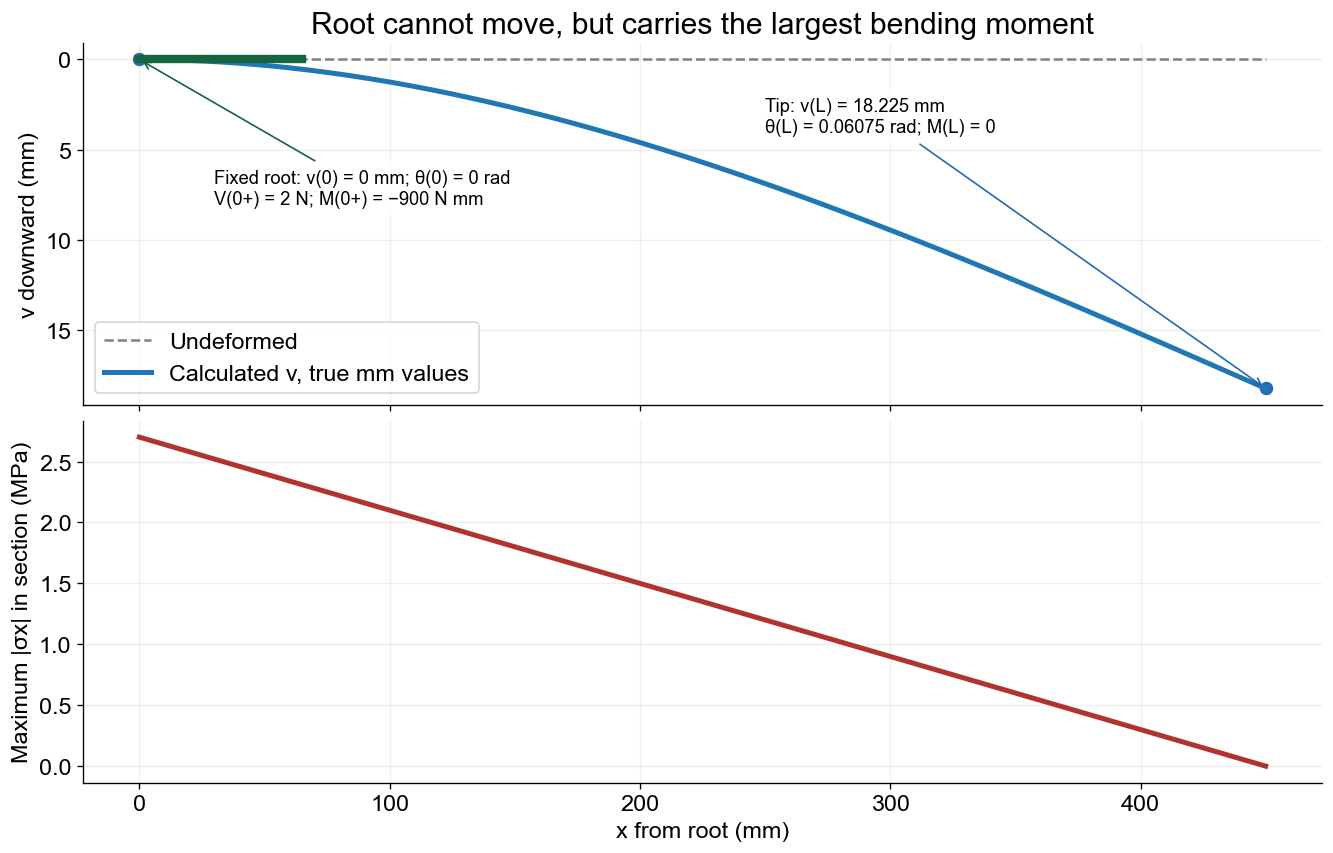

In [10]:
#@title Figure 5B — undeformed and deflected shape; stress is not displacement
v=P*x**2*(3*L-x)/(6*EI)
fig,axes=plt.subplots(2,1,figsize=(11,7),layout='constrained',sharex=True)
axes[0].plot(x,np.zeros_like(x),'--',color='gray',label='Undeformed')
axes[0].plot(x,v,lw=3,label='Calculated v, true mm values')
axes[0].scatter([0,L],[0,v[-1]],color='#236bb4',s=50)
axes[0].plot([0,65],[0,0],color='#176441',lw=5)
axes[0].annotate('Fixed root: v(0) = 0 mm; θ(0) = 0 rad\nV(0+) = 2 N; M(0+) = −900 N mm',
                 xy=(0,0),xytext=(30,8),fontsize=11,
                 bbox=dict(facecolor='white',edgecolor='none',alpha=.9),
                 arrowprops=dict(arrowstyle='->',color='#176441'))
axes[0].annotate('Tip: v(L) = 18.225 mm\nθ(L) = 0.06075 rad; M(L) = 0',
                 xy=(L,v[-1]),xytext=(250,4),fontsize=11,
                 bbox=dict(facecolor='white',edgecolor='none',alpha=.9),
                 arrowprops=dict(arrowstyle='->',color='#236bb4'))
axes[0].invert_yaxis(); axes[0].set_ylabel('v downward (mm)'); axes[0].legend()
axes[0].set_title('Root cannot move, but carries the largest bending moment')
axes[1].plot(x,np.abs(M)*h/2/I,lw=3,color='#b1322e')
axes[1].set(xlabel='x from root (mm)',ylabel='Maximum |σx| in section (MPa)')
for ax in axes: ax.grid(alpha=.2)
plt.show()
print(f'Tip deflection = {v[-1]:.4f} mm; root deflection = {v[0]:.4f} mm')
print(f'Tip slope = {P*L**2/(2*EI):.5f} rad')

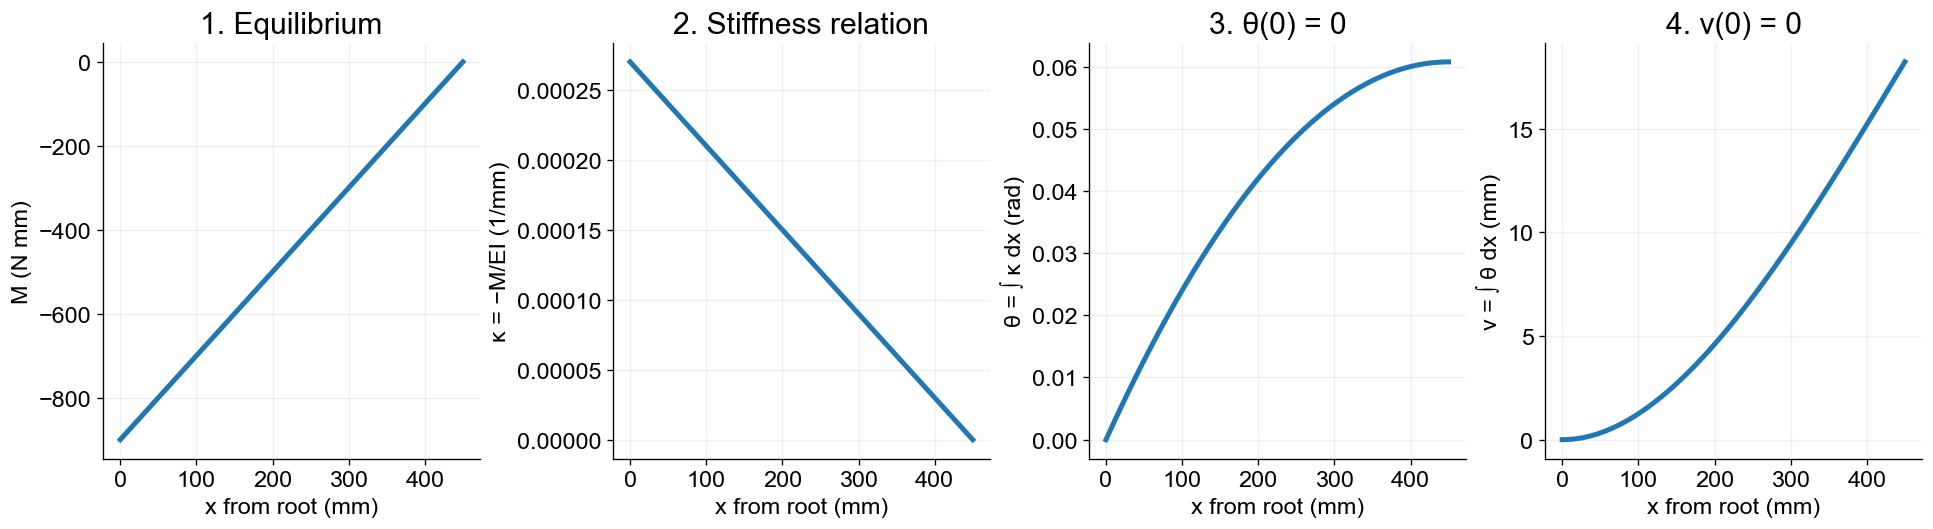

In [11]:
#@title Figure 5C — four stages of the calculation, with units
fig,axes=plt.subplots(1,4,figsize=(16,4.3),layout='constrained')
curvature=P*(L-x)/EI
theta=P*x*(2*L-x)/(2*EI)
for ax,yy,label in zip(axes,[M,curvature,theta,v],
 ['M (N mm)','κ = −M/EI (1/mm)','θ = ∫ κ dx (rad)','v = ∫ θ dx (mm)']):
    ax.plot(x,yy,lw=3)
    ax.set(xlabel='x from root (mm)',ylabel=label)
    ax.grid(alpha=.2)
axes[0].set_title('1. Equilibrium')
axes[1].set_title('2. Stiffness relation')
axes[2].set_title('3. θ(0) = 0')
axes[3].set_title('4. v(0) = 0')
plt.show()
assert abs(curvature[0]-.00027)<1e-12
assert abs(theta[-1]-.06075)<1e-12

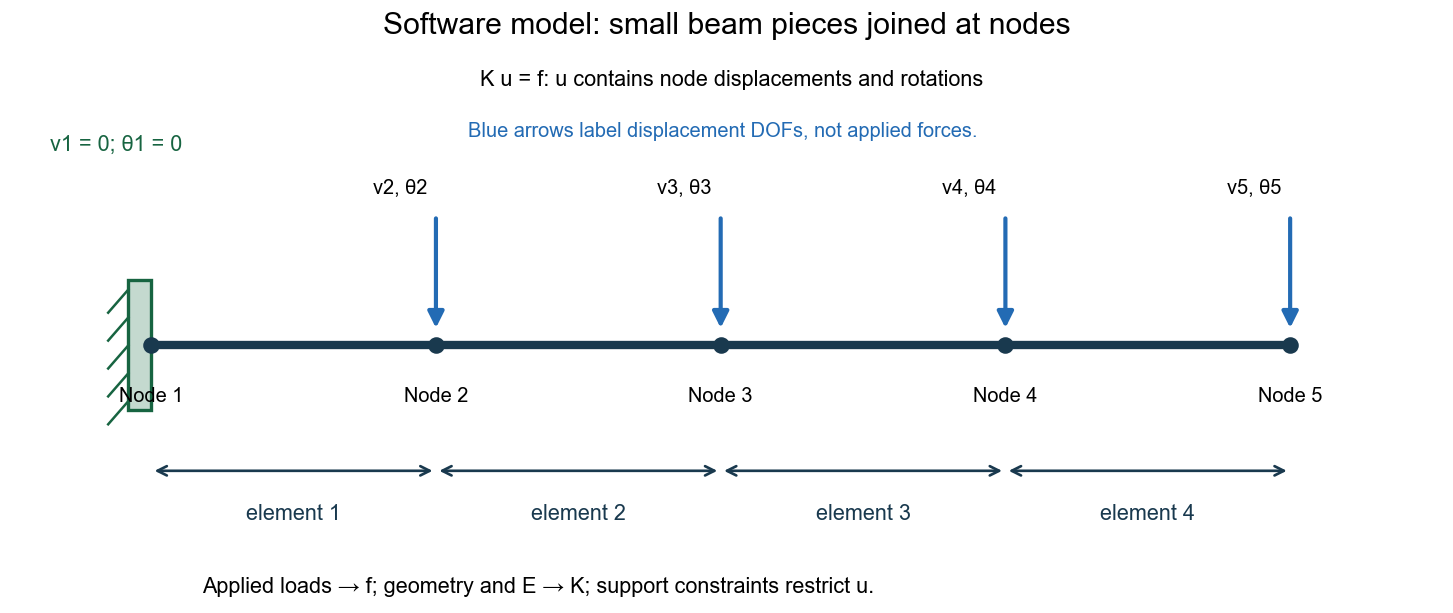

In [12]:
#@title Figure 5D — finite-element nodes carry displacement and rotation
fig,ax=plt.subplots(figsize=(12,5),layout='constrained')
clean_beam(ax,'Software model: small beam pieces joined at nodes')
support(ax,0,'fixed')
nodes=np.linspace(0,L,5)
ax.scatter(nodes,np.zeros_like(nodes),s=80,color='#19394e',zorder=5)
for j,xx in enumerate(nodes):
    ax.text(xx,-12,f'Node {j+1}',ha='center',fontsize=12)
    if j:
        arrow(ax,(xx,28),(xx,3),'#236bb4')
        ax.text(xx-25,33,f'v{j+1}, θ{j+1}',fontsize=12)
    if j<4:
        dimension(ax,(xx,-27),(nodes[j+1],-27),f'element {j+1}',(0,-9))
ax.text(-40,42,'v1 = 0; θ1 = 0',color='#176441',fontsize=13)
ax.text(130,56,'K u = f: u contains node displacements and rotations',fontsize=13)
ax.text(20,-53,'Applied loads → f; geometry and E → K; support constraints restrict u.',fontsize=13)
ax.text(125,45,'Blue arrows label displacement DOFs, not applied forces.',fontsize=12,color='#236bb4')
plt.show()

### What the app actually solves

The app divides the beam into finite elements. Each node has a displacement and rotation. Element stiffness and consistent loads assemble into:

$$\mathbf K\mathbf u=\mathbf f.$$

Boundary conditions restrict selected components of  u. After solving the free components, the original equations recover reactions. The app reconstructs shear and moment from equilibrium and evaluates stress. Refining the mesh checks numerical sensitivity; it does not verify a real clamp, printed anisotropy or material strength. You do not need to derive element matrices today.

**Software activity A:** open the tip-load link. Find −2 N, −900 N mm, 2.70 MPa and 18.225 mm. Use the probe at 150 mm and check (M=-600) N mm. Explain any sign differences before declaring an error. Download the study record.

**Interpret each output separately:** reactions check whole-beam equilibrium; V and M describe each cut; stresses describe fibres within a selected section; v describes motion along the span. A colour map of stress is not a photograph of damage. A deflection animation is usually magnified; compare the numerical mm values.

Every example link below replaces the previous study with its prescribed load and support. First compare units and sign conventions, then numerical values. Return to the notebook and record one equilibrium check and one stress/deflection calculation. Mesh convergence checks discretization, not the material model.

## 6. Example B — uniform pressure reduced to a line load

For an illustrative wing strip, a uniform pressure p over loaded width c_loaded gives q=p c_loaded. This is an applied-load idealization, not a predicted aerodynamic lift distribution. Here choose the full-span line load to have the **same 2 N total** as Example A:

$$q=\frac{F}{L}=\frac{2}{450}=0.00444444\ \mathrm{N/mm}.$$

Its resultant acts at L/2, so:

$$|C_A|=\frac{qL^2}{2}=450\ \mathrm{N\,mm},\qquad
|\sigma_{\mathrm{root}}|=\frac{qL^2h}{4I}=1.35\ \mathrm{MPa}.$$

$$v(L)=\frac{qL^4}{8EI}=6.834375\ \mathrm{mm}.$$

The root force is unchanged, root moment is half, and tip displacement is **3/8** of the point-tip case. Replacing a distributed load by its resultant gives the correct **whole-beam reactions**, but generally not the same internal diagrams or deflection. A centroid-point load of 2 N at midspan gives 5.695313 mm at the free tip, not 6.834375 mm.

**Prediction:** if we change only the direction to upward lift, what changes sign and what keeps its magnitude?

**Calculate a cut under the uniform load:** the outboard length is L − x, its total load is q(L − x), and its centroid is (L − x)/2 from the cut. Multiplying force by that lever arm gives:

$$V(x)=q(L-x),\qquad M(x)=-\frac{q(L-x)^2}{2}.$$

At x = 150 mm, V = 1.33333 N and M = −200 N mm. At the root, |M| = 450 N mm; inserting that moment and c = 5 mm into |σ| = |M|c/I gives 1.35 MPa. The same total force is not enough to specify the whole response.

Integrating −M/EI with the same root constraints gives the full displacement used to plot Figure 6B:

$$v(x)=\frac{qx^2}{24EI}\left(6L^2-4Lx+x^2\right).$$

Its tip value qL⁴/(8EI) is derived by substituting x = L, not by treating the distributed load as a tip force. For a positive lift analogue, use the upward link: the app's q is negative, displacement becomes upward, and top stress becomes compressive. Magnitudes stay unchanged in this linear model.

[Open and solve Example B — uniform 2 N downward](https://ehsan-roohi.github.io/Aerospace-Structures/wing-lab.html?beamCase=l03-uniform) · [Open and solve Example B extension — uniform upward lift](https://ehsan-roohi.github.io/Aerospace-Structures/wing-lab.html?beamCase=l03-lift)

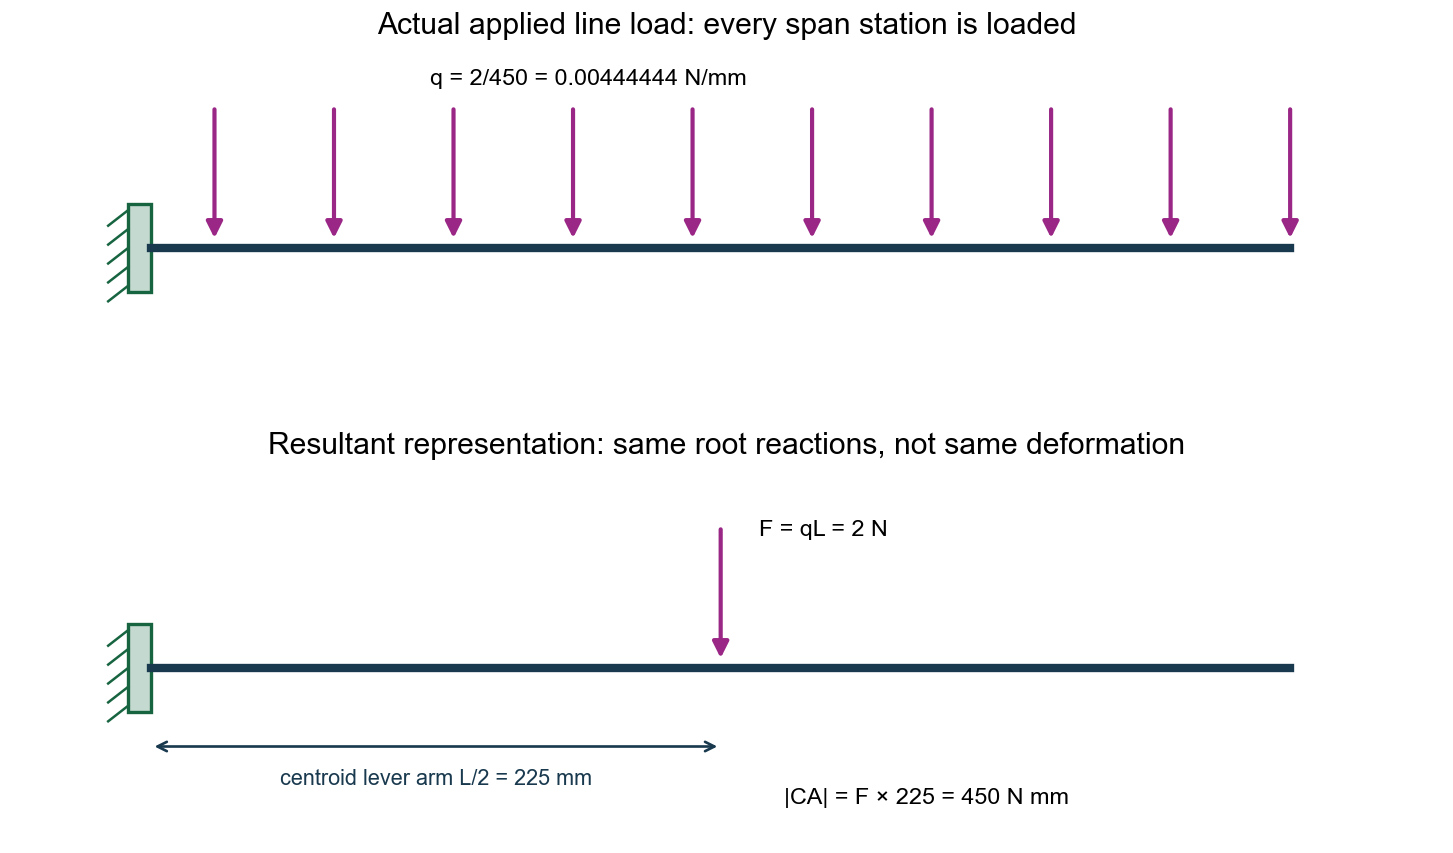

In [13]:
#@title Figure 6A — line load versus its whole-beam resultant
fig,axes=plt.subplots(2,1,figsize=(12,7),layout='constrained')
for ax,title in zip(axes,['Actual applied line load: every span station is loaded',
                         'Resultant representation: same root reactions, not same deformation']):
    clean_beam(ax,title); support(ax,0,'fixed')
for at in np.linspace(25,L,10): arrow(axes[0],(at,45),(at,2))
axes[0].text(110,52,'q = 2/450 = 0.00444444 N/mm')
arrow(axes[1],(L/2,45),(L/2,2))
axes[1].text(240,42,'F = qL = 2 N')
dimension(axes[1],(0,-25),(L/2,-25),'centroid lever arm L/2 = 225 mm',(0,-10))
axes[1].text(250,-43,'|CA| = F × 225 = 450 N mm')
plt.show()

Uniform: root |M|=450.000 N mm; stress=1.350 MPa; tip v=6.834375 mm


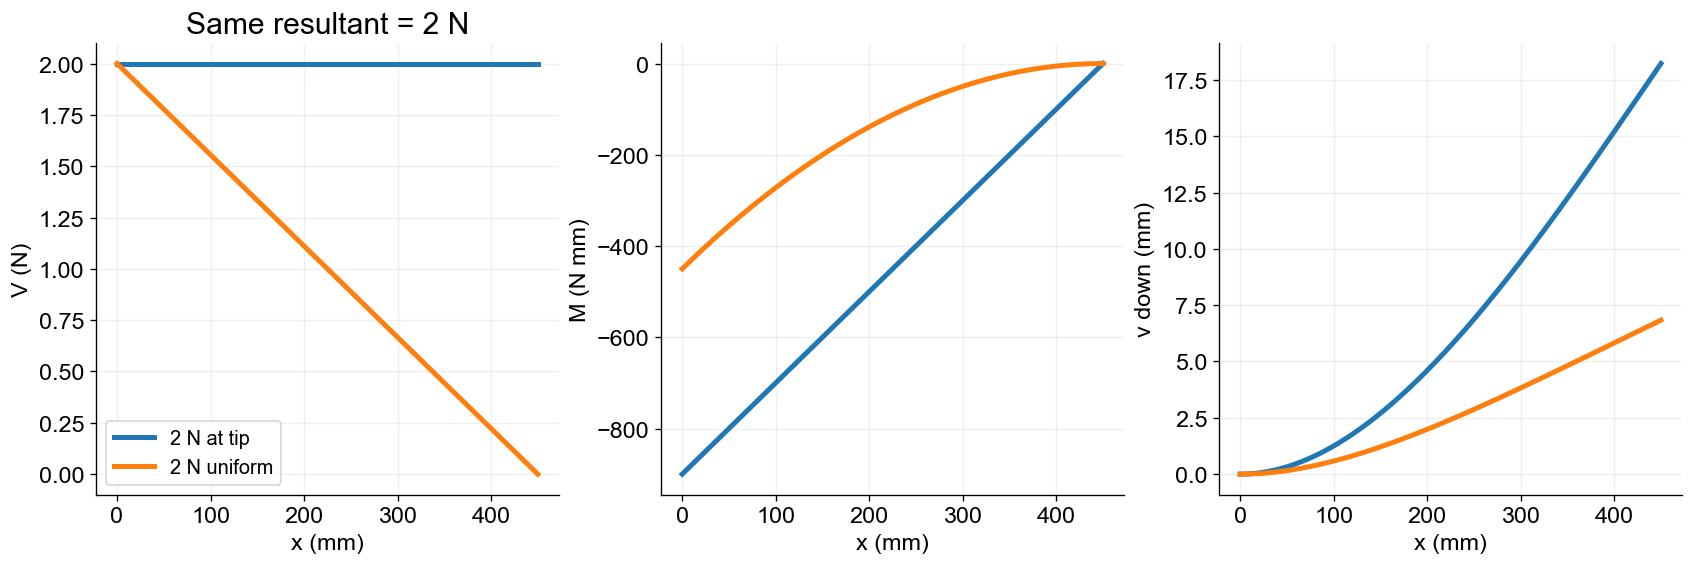

In [14]:
#@title Figure 6B — equal total load, different internal diagrams and displacement
q=P/L
Vu=q*(L-x); Mu=-q*(L-x)**2/2
vu=q*x**2*(6*L**2-4*L*x+x*x)/(24*EI)
fig,axes=plt.subplots(1,3,figsize=(14,4.6),layout='constrained')
for ax,y1,y2,label in zip(axes,[V,M,v],[Vu,Mu,vu],['V (N)','M (N mm)','v down (mm)']):
    ax.plot(x,y1,lw=3,label='2 N at tip'); ax.plot(x,y2,lw=3,label='2 N uniform')
    ax.set(xlabel='x (mm)',ylabel=label); ax.grid(alpha=.2)
axes[0].legend(fontsize=12); axes[0].set_title('Same resultant = 2 N')
plt.show()
print(f'Uniform: root |M|={q*L**2/2:.3f} N mm; stress={q*L**2*h/(4*I):.3f} MPa; tip v={vu[-1]:.6f} mm')

## 7. Example C — change only the support conditions

Keep P=2 N, L=450 mm, the same section and E, but place the load at **midspan**. This might represent a laboratory coupon tested between fixtures. It is not a second aircraft wing-root model.

For the symmetric simply supported beam, equilibrium gives R_A=R_B=P/2. Neither support supplies an end moment:

$$M_{\max}=\frac{PL}{4}=225\ \mathrm{N\,mm},\qquad
|\sigma_{\max}|=0.675\ \mathrm{MPa},\qquad
v_{\max}=\frac{PL^3}{48EI}=1.139063\ \mathrm{mm}.$$

For the symmetric fixed–fixed beam, compatibility produces end hogging moments M(0)=M(L)=-PL/8 and centre sagging moment +PL/8:

$$|M|_{\max}=\frac{PL}{8}=112.5\ \mathrm{N\,mm},\qquad
|\sigma_{\max}|=0.3375\ \mathrm{MPa},\qquad
v_{\max}=\frac{PL^3}{192EI}=0.284766\ \mathrm{mm}.$$

Its app reactions are −1 N at each end, with clockwise-positive couples **−112.5 N mm at A and +112.5 N mm at B**. This is why support reaction-couple signs and internal moment signs should not be interchanged. A fixed–fixed beam can have maximum stress at both supports and at the centre for this symmetric load. Clamping changes the moment distribution; it does not merely multiply every stress by a universal factor.

We use these standard results today; a full compatibility derivation is after-class work. Do not try to solve the redundant end moments using equilibrium alone.

### Follow one numerical substitution in each case

Symmetry and vertical equilibrium give 1 N upward at each end. For the simply supported beam, the left-half cut moment is M(x) = (P/2)x. At x = L/2 it is (1 N)(225 mm) = 225 N mm. Multiplying by c/I gives 0.675 MPa. The centre displacement follows from integrating curvature with zero end displacements and symmetry (zero slope at the centre).

For fixed–fixed, end rotation must also vanish. On the left half write M(x) = M₀ + (P/2)x, where M₀ is initially unknown. With θ(0) = 0, integrating curvature to the centre gives:

$$\theta(L/2)=-\frac{1}{EI}\left(M_0\frac{L}{2}+\frac{PL^2}{16}\right)=0.$$

Thus M₀ = −PL/8. It is **compatibility of rotation**, not a fourth equilibrium equation, that finds this redundant moment. Integrating once more with v(0) = 0 gives, on 0 ≤ x ≤ L/2:

$$v_{\mathrm{fixed}}(x)=\frac{PLx^2}{16EI}-\frac{Px^3}{12EI},\qquad
v_{\mathrm{simple}}(x)=\frac{PL^2x}{16EI}-\frac{Px^3}{12EI}.$$

The right halves follow by symmetry. Substitution at x = L/2 produces the quoted centre-deflection formulas. Use the pictures and comparisons during class; the algebra is a supporting reading rather than another full in-class derivation.

[Open and solve Example C1 — pin–roller and centre load](https://ehsan-roohi.github.io/Aerospace-Structures/wing-lab.html?beamCase=l03-simple) · [Open and solve Example C2 — fixed–fixed and centre load](https://ehsan-roohi.github.io/Aerospace-Structures/wing-lab.html?beamCase=l03-fixed)

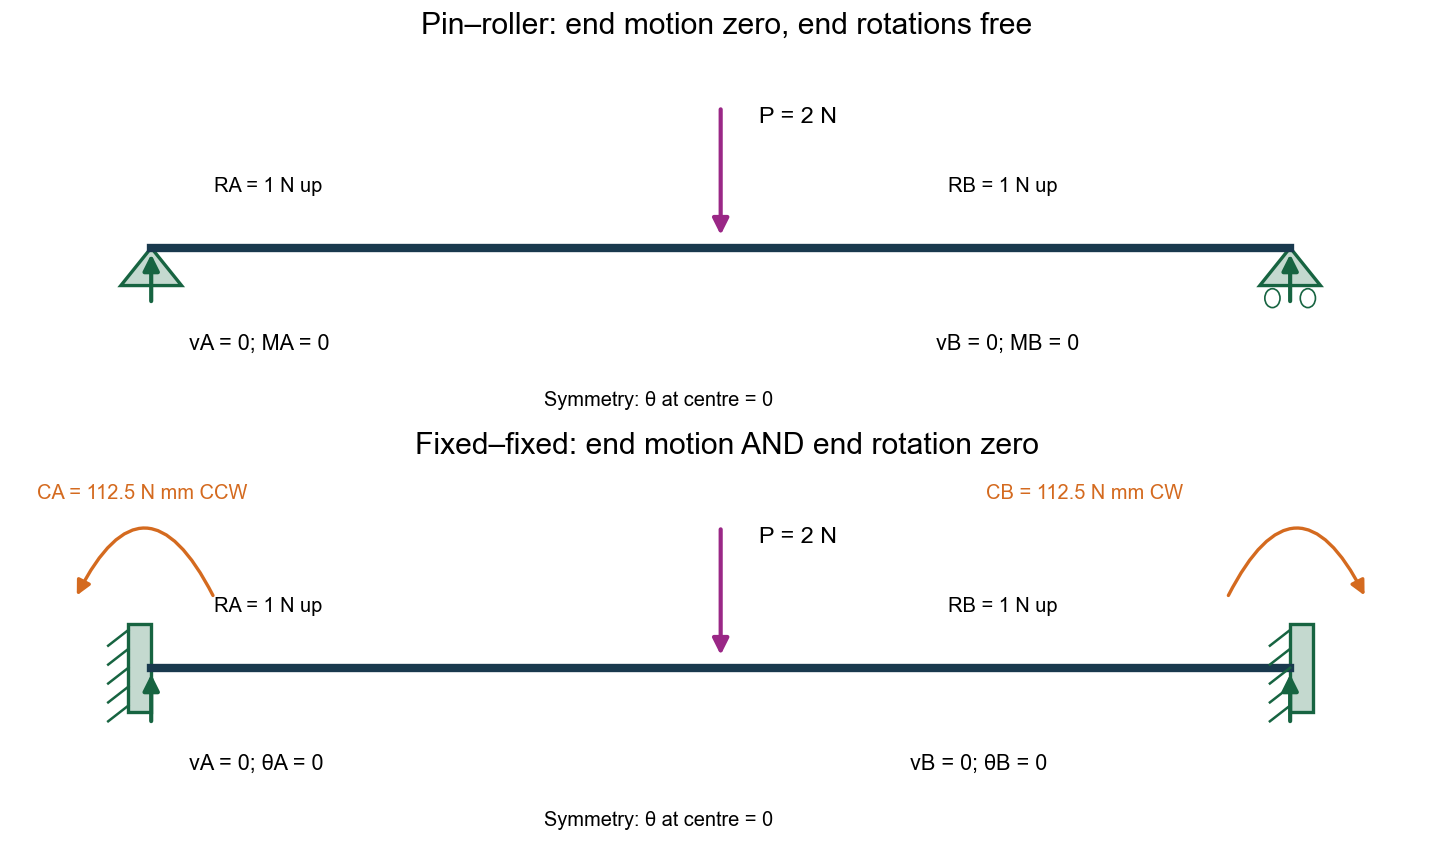

In [15]:
#@title Figure 7A — constraints determine the centre-load comparison
fig,axes=plt.subplots(2,1,figsize=(12,7),layout='constrained')
for ax,title in zip(axes,['Pin–roller: end motion zero, end rotations free',
                         'Fixed–fixed: end motion AND end rotation zero']):
    clean_beam(ax,title)
    arrow(ax,(L/2,45),(L/2,3)); ax.text(240,40,'P = 2 N')
support(axes[0],0,'pin');support(axes[0],L,'roller')
support(axes[1],0,'fixed');support(axes[1],L+9,'fixed')
axes[0].text(15,-32,'vA = 0; MA = 0',fontsize=13)
axes[0].text(310,-32,'vB = 0; MB = 0',fontsize=13)
axes[1].text(15,-32,'vA = 0; θA = 0',fontsize=13)
axes[1].text(300,-32,'vB = 0; θB = 0',fontsize=13)
for ax in axes:
    arrow(ax,(0,-18),(0,-1),'#176441');arrow(ax,(L,-18),(L,-1),'#176441')
    ax.text(25,18,'RA = 1 N up',fontsize=12)
    ax.text(315,18,'RB = 1 N up',fontsize=12)
    ax.text(155,-50,'Symmetry: θ at centre = 0',fontsize=12)
axes[1].add_patch(FancyArrowPatch((25,22),(-30,22),connectionstyle='arc3,rad=1',
                                 arrowstyle='-|>',mutation_scale=18,color='#d46a1f',lw=2))
axes[1].add_patch(FancyArrowPatch((L-25,22),(L+30,22),connectionstyle='arc3,rad=-1',
                                 arrowstyle='-|>',mutation_scale=18,color='#d46a1f',lw=2))
axes[1].text(-45,54,'CA = 112.5 N mm CCW',fontsize=12,color='#d46a1f')
axes[1].text(330,54,'CB = 112.5 N mm CW',fontsize=12,color='#d46a1f')
plt.show()

Pin–roller: max |M|=225.0000 N mm; max |σ|=0.675000 MPa; max v=1.139063 mm
Fixed–fixed: max |M|=112.5000 N mm; max |σ|=0.337500 MPa; max v=0.284766 mm


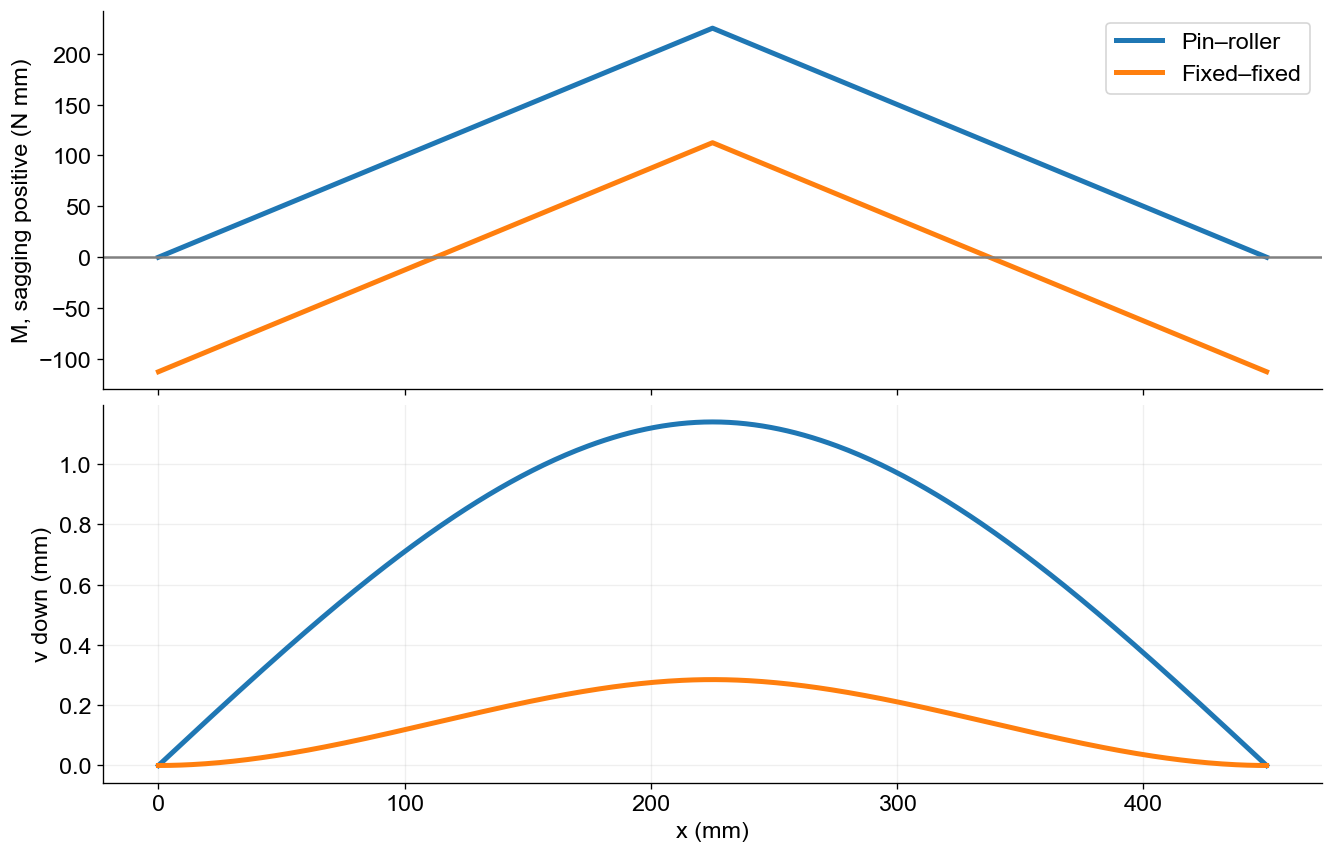

In [16]:
#@title Figure 7B — simply supported versus fixed–fixed, same centre force
Ms=np.where(x<=L/2,P*x/2,P*(L-x)/2)
Mf=Ms-P*L/8
xx=np.minimum(x,L-x)
vs=P*xx*(3*L**2-4*xx**2)/(48*EI)
vf=P*xx**2*(3*L-4*xx)/(48*EI)
fig,axes=plt.subplots(2,1,figsize=(11,7),layout='constrained',sharex=True)
axes[0].plot(x,Ms,lw=3,label='Pin–roller'); axes[0].plot(x,Mf,lw=3,label='Fixed–fixed')
axes[0].axhline(0,color='gray'); axes[0].set_ylabel('M, sagging positive (N mm)'); axes[0].legend()
axes[1].plot(x,vs,lw=3,label='Pin–roller'); axes[1].plot(x,vf,lw=3,label='Fixed–fixed')
axes[1].set(xlabel='x (mm)',ylabel='v down (mm)'); axes[1].grid(alpha=.2)
plt.show()
for name,mm,vv in [('Pin–roller',Ms,vs),('Fixed–fixed',Mf,vf)]:
    print(f'{name}: max |M|={max(abs(mm)):.4f} N mm; max |σ|={max(abs(mm))*h/(2*I):.6f} MPa; max v={max(vv):.6f} mm')

## 8. Return to the aircraft wing

For an upward-loaded wing, top material is commonly in spanwise compression and bottom material in tension under positive lift bending. The root transfers shear and a bending couple to the fuselage. In a deep spar, the caps carry much of the bending tension/compression and the web carries shear. Skins and stringers also participate; ribs preserve section shape and transfer local loads. Adding a rib does not erase the externally applied lift.

$$I_{\mathrm{rectangle}}\propto h^3,\qquad \sigma_{\max}\propto h^{-2},\qquad v\propto h^{-3}$$

These scalings require fixed width, material, length and load in our solid-rectangle model. Doubling h increases section mass by two, reduces bending stress to one quarter and deflection to one eighth. Increasing E reduces deflection but does **not** reduce bending stress in this statically determinate cantilever under the same force. Actual thin-walled wing sections need their own EI, geometry and material distribution.

**Do not confuse:** force N; moment N mm; stress MPa; displacement mm; strain dimensionless; slope rad. Strength, stiffness and buckling resistance are distinct requirements. A tip test force is a structural test input, not automatically a flight load. Load factor n=L_aero/W describes an aerodynamic loading condition; factor of safety is a different quantity.

**Locate the cause, not only the maximum:** the long lever arm of outboard load makes root moment large. The nominal bending stress also depends on local section depth and I. For a tapered wing the largest stress is not automatically at the root; compare |M|c/I along the span. Root fittings introduce local stress concentrations that the elementary beam does not resolve.

In this notebook bending occurs about the transverse y-axis; torsion is rotation about the longitudinal x-axis. The next optional orientation figure identifies the axes and a torque lever arm. The rectangular I used for bending is **not** the torsional constant J. The introductory beam links solve bending only; they do not calculate the optional shaft twist below.

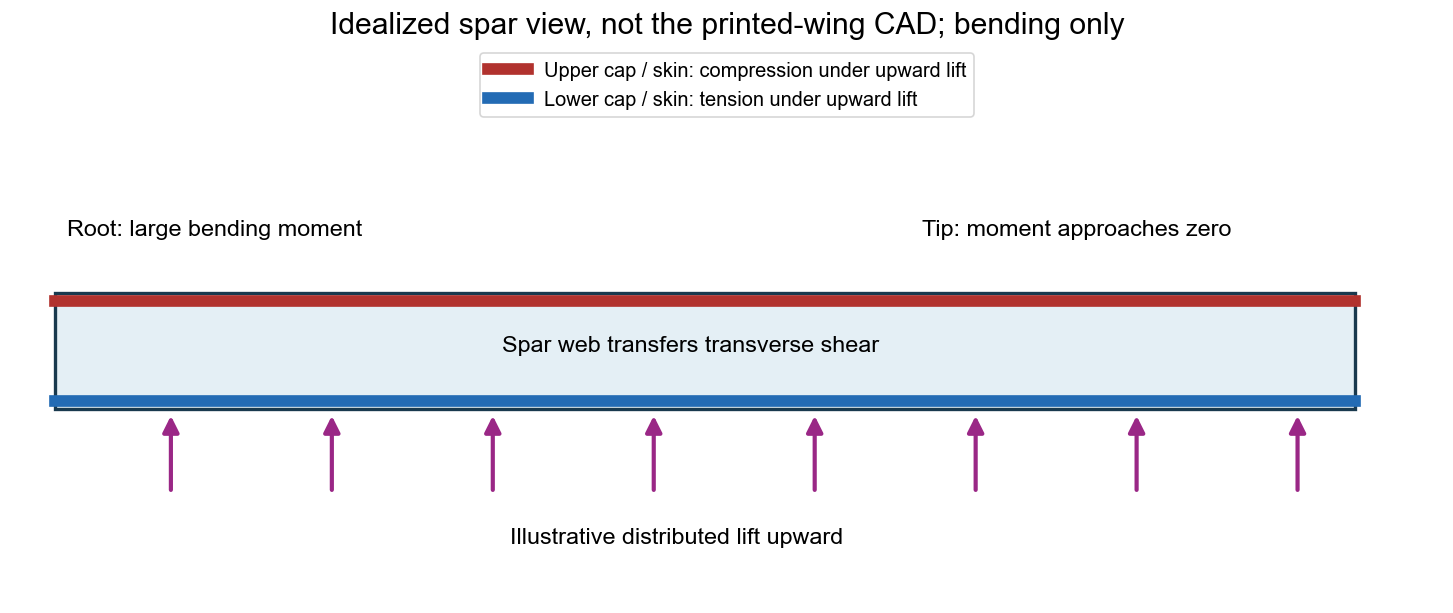

In [17]:
#@title Figure 8 — a wing spar turns bending into a separated force couple
fig,ax=plt.subplots(figsize=(12,5),layout='constrained')
ax.add_patch(Rectangle((0,0),450,30,facecolor='#e4eff5',edgecolor='#19394e',lw=2))
ax.plot([0,450],[28,28],color='#b1322e',lw=7,label='Upper cap / skin: compression under upward lift')
ax.plot([0,450],[2,2],color='#236bb4',lw=7,label='Lower cap / skin: tension under upward lift')
for at in np.linspace(40,430,8): arrow(ax,(at,-22),(at,-1),'#9a2786')
ax.text(215,-35,'Illustrative distributed lift upward',ha='center')
ax.text(220,15,'Spar web transfers transverse shear',ha='center',fontsize=14)
ax.text(4,45,'Root: large bending moment',fontsize=14)
ax.text(300,45,'Tip: moment approaches zero',fontsize=14)
ax.set(xlim=(-15,480),ylim=(-50,95)); ax.axis('off'); ax.legend(loc='upper center',fontsize=12)
ax.set_title('Idealized spar view, not the printed-wing CAD; bending only')
plt.show()

### Optional orientation — distinguish a bending moment from torque

Use this as a visual bridge to a wing's twisting motion, not as a new 90-minute beam exercise. A vertical force on a spanwise lever produces bending; a tangential force with offset r from the longitudinal axis produces torque about that axis:

$$T=F_t r.$$

For a straight homogeneous circular tube under Saint-Venant torsion:

$$J=\frac{\pi}{2}(R_o^4-R_i^4),\qquad
\phi=\frac{T\ell}{GJ},\qquad \tau(r)=\frac{Tr}{J}.$$

The optional figure labels ℓ, outer radius Rₒ, inner radius Rᵢ, force Fₜ, lever r, torque T, axis x and rotation φ. G is the material shear modulus; J is calculated from the cross-sectional radii. This circular-tube formula does not apply to the rectangular teaching beam or directly to a multi-cell wing box. A torsional couple is not the sagging bending moment M in the earlier formulas.

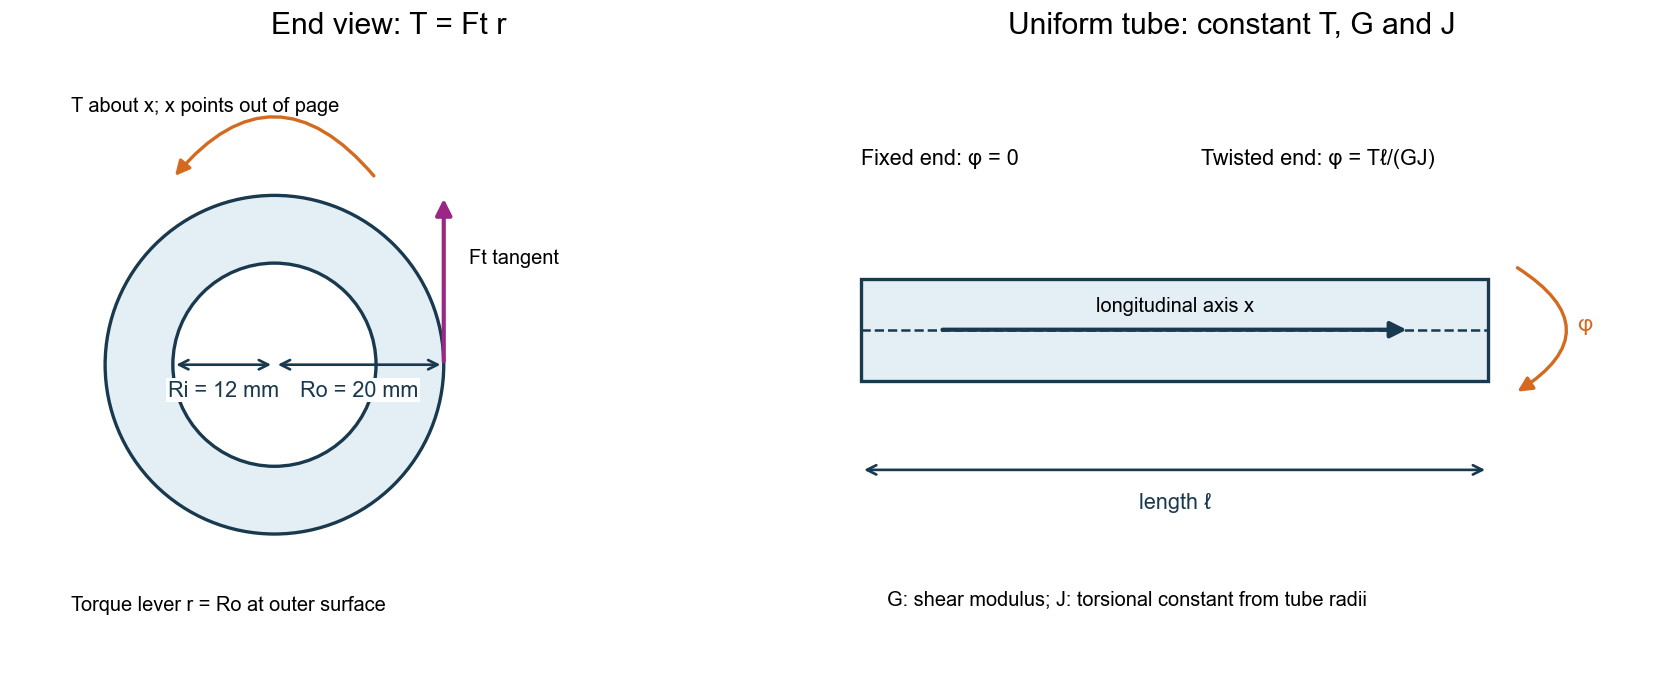

In [18]:
#@title Optional Figure 9 — torsion symbols on a circular tube, not the beam solver
fig,axes=plt.subplots(1,2,figsize=(14,5.5),layout='constrained')
ax=axes[0]
Ro,Ri=20.,12.
ax.add_patch(Circle((0,0),Ro,facecolor='#e4eff5',edgecolor='#19394e',lw=2))
ax.add_patch(Circle((0,0),Ri,facecolor='white',edgecolor='#19394e',lw=2))
dimension(ax,(0,0),(Ro,0),'Ro = 20 mm',(0,-3))
dimension(ax,(0,0),(-Ri,0),'Ri = 12 mm',(0,-3))
arrow(ax,(Ro,0),(Ro,20),'#9a2786');ax.text(23,12,'Ft tangent',fontsize=12)
ax.add_patch(FancyArrowPatch((12,22),(-12,22),connectionstyle='arc3,rad=.6',
                            arrowstyle='-|>',mutation_scale=18,color='#d46a1f',lw=2))
ax.text(-24,30,'T about x; x points out of page',fontsize=12)
ax.text(-24,-29,'Torque lever r = Ro at outer surface',fontsize=12)
ax.set(xlim=(-31,58),ylim=(-35,38),title='End view: T = Ft r');ax.set_aspect('equal');ax.axis('off')
ax=axes[1]
ax.add_patch(Rectangle((0,-8),120,16,facecolor='#e4eff5',edgecolor='#19394e',lw=2))
ax.plot([0,120],[0,0],'--',color='#19394e')
dimension(ax,(0,-22),(120,-22),'length ℓ',(0,-5))
arrow(ax,(15,0),(105,0),'#19394e');ax.text(60,3,'longitudinal axis x',ha='center',fontsize=12)
ax.text(0,26,'Fixed end: φ = 0',fontsize=13)
ax.text(65,26,'Twisted end: φ = Tℓ/(GJ)',fontsize=13)
ax.add_patch(FancyArrowPatch((125,10),(125,-10),connectionstyle='arc3,rad=-.8',
                            arrowstyle='-|>',mutation_scale=18,color='#d46a1f',lw=2))
ax.text(137,0,'φ',fontsize=14,color='#d46a1f')
ax.text(5,-43,'G: shear modulus; J: torsional constant from tube radii',fontsize=12)
ax.set(xlim=(-8,150),ylim=(-52,45),title='Uniform tube: constant T, G and J');ax.axis('off')
plt.show()

## 9. Four-minute exit ticket and after-class practice

Submit one page with: a labelled free body; reaction unknowns and constraints; one equilibrium check; one moment-to-stress calculation; one deflection calculation; the app study record; and a sentence explaining the largest stress and displacement locations. Use units on every numerical result.

1. Why is root displacement zero while root stress can be largest?
2. Why do two 2 N loads have different moments and deflections?
3. Which extra information is needed for a fixed–fixed beam beyond equilibrium?
4. If an app returns zero deflection, where was the load placed and what motions were restrained?

**After class, not part of the 90-minute route:** change one parameter at a time. Predict and test P×2, E×2 and h×2. Then explore the triangle/trapezoid options from Lecture 02, keeping total force fixed. Reactions and stress checks should precede vibration modes.

### Reading and model scope

[TU Delft beam theory and finite elements](https://teachbooks.tudelft.nl/computational-modelling/structural_linear/euler_bernouilli.html) supports the equilibrium–curvature–boundary-condition framework. Our diagrams are original instructional illustrations. Numerical examples use declared assumed dimensions/material values and closed-form elastic beam solutions, independently checked against the course beam engine. Scope: straight, slender, homogeneous solid section; constant EI; ideal supports; linear elasticity and small displacement; no self-weight unless specified. This is not an airworthiness or printed-wing failure certification.